# 后续整理：3.4—3.7

作者：林泓浩。以新增手稿与既有讲解为依据，含每节练习及参考答案、原书15题全部小问解答。公式编号与本次PDF相同；代码已实际执行。需要numpy、pandas、matplotlib、scipy、statsmodels、ISLP、scikit-learn。工作目录设为本Notebook所在文件夹。

## 营销计划（The Marketing Plan）

<a id="ref-sec-34"></a>

> 整理依据：新增手稿第一页的四个“GPT”标注，以及本次对话中已经学习的营销问题、非线性与交互例子。手稿问题保留为思考，说明与答案按已学内容补齐。

**本节目标**

把前面分散的统计量组织成业务分析：有没有关系、哪些变量有信息、关联有多大、预测有多准、是否遗漏弯曲关系与渠道交互。显著性、拟合优度与泛化能力分别回答不同问题。

<a id="ref-topic-marketing-map"></a>

### 思考51　面对广告预算与销量，应依次问什么？

一家企业想根据电视、广播和报纸广告预算分析销量。首先明确目标是描述关联、预测新市场，还是评估投放的因果效果；普通观察数据回归不能自动完成第三个目标。以下七个问题对应原书主线。

- 是否至少有一种渠道与销量存在模型中的线性关联？看整体 F 检验，原假设是所有非截距系数同时为零，见[式（3.125）](#ref-eq-overall-f)。

- 关联强不强？用 RSE 描述原单位上的残差尺度，用 $R^2$ 描述相对于均值基线的平方误差改善；二者见[式（3.87）](#ref-eq-rse-simple)、[式（3.89）](#ref-eq-tss-r2)。

- 哪些渠道在控制其他渠道后仍有额外关联？逐个斜率的 t 检验见[式（3.123）](#ref-eq-multi-t)；多个新增项应使用[式（3.130）](#ref-eq-partial-f)。

- 关联大小是多少，估计稳定吗？同时报告系数、单位与置信区间，不只报告 p 值。

- 给定预算，预测的是平均销量还是一个新市场的销量？分别使用[式（3.141）](#ref-eq-prediction-intervals)的两个区间。

- 残差是否显示直线遗漏了非线性规律？见[式（3.155）](#ref-eq-residual-misspec)。

- 一个渠道的斜率是否随另一渠道预算改变？这需要交互项，而不是仅添加两个主效应。

原书 Advertising 示例的训练 $R^2$ 约为 0.897，RSE 约为 1.69（销量单位为千件）。它们描述当前拟合；$1.69$ 除以平均销量只能作为相对尺度，不能把它叫作 MAPE，也不能当成未来每个市场的保证误差。

### 练习 3.72　显著关系是否一定强

整体检验 $p=0.001$，但训练 $R^2=0.08$，二者矛盾吗？

**参考答案**

不矛盾。前者在相应假设下反对“所有斜率为零”，后者说明当前模型只解释约 8% 的训练响应平方波动。样本多时很小的效应也可能显著；还应检查单位、区间与验证误差。

### 练习 3.73　简单回归与控制其他渠道后的结果

报纸广告在简单回归中显著，加入电视与广播后不显著，能否认为计算错误或报纸绝对无用？

**参考答案**

都不能。简单回归描述边际关联，多元回归描述控制其他变量后的额外线性关联；相关的渠道预算可解释这种变化。未拒绝不等于证明零效应，统计关联也不等于因果作用。

<a id="ref-topic-marketing-size"></a>

### 思考52　怎样把系数与区间翻译成业务量？

以下是虚构例子，预算单位万元、销量单位千件，不与原书 Advertising 的单位混用。若拟合均值为

<a id="ref-eq-ext-marketing-mean"></a>

$$
\widehat f(T,R)=5+0.3T+0.1R,
\tag{3.165}
$$

保持广播预算 $R$ 不变，电视预算增加 2 万元，拟合平均销量增加 $0.3\times2=0.6$ 千件。若电视斜率区间为 $[0.1,0.5]$，则这个固定预算增量对应的平均差异区间是 $[0.2,1.0]$ 千件；这不是一个新市场的个体预测区间。

在 $T=10,R=20$ 时，点预测是 10。假设 $s=2,h_0=0.25$，用临界值近似 2 说明计算：

<a id="ref-eq-ext-marketing-interval"></a>

$$
\begin{aligned}
\text{平均响应区间}&:\quad 10\pm2\sqrt{4\times0.25}=[8,12],\\
\text{新市场预测区间}&:\quad 10\pm2\sqrt{4(1+0.25)}\approx[5.53,14.47].
\end{aligned}
\tag{3.166}
$$

引用[式（3.135）](#ref-eq-mean-variance)和[式（3.136）](#ref-eq-prediction-variance)可见，多出来的是新观测自身的噪声。不能把“平均规律估计得准”误当成“每个市场都接近平均值”。

### 练习 3.74　预算增量与区间

电视系数为 0.2，95% 置信区间 $[0.1,0.3]$，预算增加 3 万元，其他变量固定。平均响应估计变化及对应区间是多少？

**参考答案**

变化为 $0.2\times3=0.6$ 千件，区间为 $[0.3,0.9]$ 千件。由于乘数3为正，端点保持顺序；这是系数所对应的平均响应对比，不是新观测预测区间。

### 练习 3.75　预测一个新市场

要估计明天一个具体新市场的销量，应使用平均响应置信区间还是个体预测区间？

**参考答案**

使用新观测预测区间。该市场除了均值估计不确定性，还有自身随机波动；独立、同方差等相应条件下方差相加，见[式（3.136）](#ref-eq-prediction-variance)。

<a id="ref-topic-hand34-1"></a>

### 思考53　手稿思考 1：系数显著、R² 很高，就说明直线模型合适吗？

不能。显著性检验针对模型参数，$R^2$ 衡量当前平方误差改善，都没有逐个检查局部均值形式。沿用之前的无噪声例子 $x=0,1,2,3,4$、$y=2+x^2$：最小二乘直线为 $\widehat y=4x$，残差为 $(2,-1,-2,-1,2)$，详见[式（3.154）](#ref-eq-u-residual)。两端低估、中间高估，说明直线遗漏了弯曲规律，即使残差和为零也不能否认。真实数据应结合残差图、业务机制与验证表现判断。

<a id="ref-topic-hand34-2"></a>

### 思考54　手稿思考 2：电视广告的关联大小会不会随预算而改变？

在加性直线模型[式（3.165）](#ref-eq-ext-marketing-mean)中，电视斜率恒为0.3，不随自身或广播预算变化。这是模型施加的限制，不是数据的必然事实。若希望电视斜率随广播预算变化，可写

<a id="ref-eq-ext-interaction"></a>

$$
f(T,R)=\beta_0+\beta_TT+\beta_RR+\beta_{TR}TR.
\tag{3.167}
$$

固定 $R=r$，只改变电视预算 $\Delta T$，逐项相减：

<a id="ref-eq-ext-interaction-change"></a>

$$
\begin{aligned}
f(T+\Delta T,r)-f(T,r)
&=\beta_T\Delta T+\beta_{TR}r\Delta T\\
&=(\beta_T+\beta_{TR}r)\Delta T.
\end{aligned}
\tag{3.168}
$$

例如 $f(T,R)=5+0.3T+0.1R+0.02TR$，电视预算增加2万元时，$R=0$ 对应增加0.6千件；$R=20$ 对应增加1.4千件。如果讨论的是电视斜率随自身预算 $T$ 改变，则可用电视平方项表达；必须先说清“随哪个变量改变”。

<a id="ref-topic-hand34-3"></a>

### 思考55　手稿思考 3：非线性与交互作用是不是同一件事？

不是。$f(T,R)=2+T+0.5T^2+3R$ 对 $T$ 弯曲，但 $T$ 的斜率 $1+T$ 不依赖 $R$，没有两渠道交互。[式（3.167）](#ref-eq-ext-interaction)固定 $R$ 后对 $T$ 仍是一条直线，但斜率随 $R$ 改变，因此有交互。一个模型可以同时有平方项与交互项；它们对输入的结构不同，却都可以对未知系数保持线性。

<a id="ref-topic-hand34-4"></a>

### 思考56　手稿思考 4：怎样判断交互项是否需要保留？

先明确目的与层级。比较含电视、广播两个主效应的简模型，以及增加 $TR$ 的全模型。若只新增一个交互系数，可用双侧 t 检验 $H_0:\beta_{TR}=0$，也可用部分 F，且在相同经典假设下 $F=t^2$，见[式（3.129）](#ref-eq-f-t-square)。若新增一组交互项，使用联合部分 F。

统计显著性不是唯一标准：还要看效应大小与区间、业务可解释性、样本是否支持所需预算组合，以及验证误差。保留交互项时一般保留相应主效应，避免解释依赖任意零点。原书加入电视与广播交互后训练 $R^2$ 约从90%提高到97%，但训练改善不是新数据上的保证。

### 练习 3.76　交互项改变预算效果

$f(T,R)=5+0.2T+0.1R+0.01TR$。电视预算增加3，分别在 $R=10$ 与 $R=30$ 时，均值增加多少？

**参考答案**

由[式（3.168）](#ref-eq-ext-interaction-change)，分别为 $(0.2+0.01\times10)\times3=0.9$ 与 $(0.2+0.01\times30)\times3=1.5$。不能在两种情境都只用主效应 $0.2\times3$。

### 练习 3.77　有弯曲就有交互吗

$f(T,R)=2+T+0.5T^2+3R$ 是否对 $T$ 非线性？是否存在 $T$ 与 $R$ 的交互？

**参考答案**

对 $T$ 非线性；但没有交互，因为 $T$ 的斜率 $1+T$ 不依赖 $R$，而 $R$ 的斜率恒为3。

**本节提醒**

把“有没有关联”“关联有多大”“模型形式合理吗”“新数据预测如何”分开回答。下一节去掉预先指定直线的限制，用局部邻居估计均值，代价是更依赖距离与局部数据。

## 线性回归与 K 近邻的比较（Comparison of Linear Regression with K-Nearest Neighbors）

<a id="ref-sec-35"></a>

> 整理依据：新增手稿第二页。保留手写的固定设计、条件噪声假设、KNN 分解、方差与偏差公式；“GPT”处使用此前广告预算例子和线性模型比较。尺度与维数部分来自后续已学内容。

**本节目标**

不预先规定平均关系是一条直线，能否从数据预测？理解局部平均的来源，推导多取邻居为何降噪、为何可能引入偏差，再判断数据量和维数是否支持这种方法。

<a id="ref-topic-ext-knn-rule"></a>

### 思考57　先找到相似市场，再平均它们的销量

虚构五个市场的广告预算为 $(10,20,30,40,50)$ 万元，销量为 $(4,6,8,9,11)$ 千件。预测预算 $x_0=32$ 的市场，距离为 $(22,12,2,8,18)$。当 $K=3$，最近的输入为 $30,40,20$，对应销量为 $8,9,6$，因此

<a id="ref-eq-ext-knn-predict"></a>

$$
\widehat f_K(x_0)=\frac1K\sum_{i\in N_K(x_0)}Y_i,\qquad
\widehat f_3(32)=\frac{8+9+6}{3}=\frac{23}{3}.
\tag{3.169}
$$

$N_K(x_0)$ 是最近的K个训练观测的索引集合，只根据输入和预先选定的距离确定，不能根据销量挑“结果接近”的邻居。KNN回归平均数值响应；KNN分类估计类别比例并作决策。

为什么取平均？固定这些邻居，用一个常数c代表它们，最小化局部平方误差。

<a id="ref-eq-ext-knn-local-ls"></a>

$$
\begin{aligned}
Q(c)&=\sum_{i\in N_K}(Y_i-c)^2,\\
Q'(c)&=-2\sum_{i\in N_K}(Y_i-c)=0
\quad\Longrightarrow\quad c=\frac1K\sum_{i\in N_K}Y_i,\\
Q''(c)&=2K>0.
\end{aligned}
\tag{3.170}
$$

严格凸性保证这个驻点是唯一最小值。$K=1$ 时在该输入预测8；$K=5$ 时所有位置都预测全体均值7.6。最后一种预测忽略了输入位置。

<a id="ref-code-350-01"></a>

### 代码 3.5-01　手工核对 KNN 邻居与平均预测

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/350-01.html)

In [45]:
import numpy as np
x_knn = np.array([10., 20., 30., 40., 50.])
y_knn = np.array([4., 6., 8., 9., 11.])
query = 32.
distance = np.abs(x_knn - query)
neighbors = np.argsort(distance)[:3]
print('neighbor positions:', neighbors)
print('neighbor inputs:', x_knn[neighbors])
print('prediction:', y_knn[neighbors].mean())

neighbor positions: [2 3 1]
neighbor inputs: [30. 40. 20.]
prediction: 7.666666666666667


**逐步读代码**

`np.abs` 对每个差取绝对值；一维欧氏距离就是绝对差。`np.argsort` 返回距离从小到大的位置，而不是距离本身；`[:3]` 取前三个位置。用同一组位置选择输入和响应，再对响应求平均。邻居只由输入决定，没有使用目标值来选择。

### 练习 3.78　手算另一位置的近邻

沿用五个市场，预测 $x_0=38$，$K=3$。邻居是谁，预测多少？

**参考答案**

距离为28、18、8、2、12；选输入40、30、50，对应9、8、11，预测 $28/3\approx9.333$ 千件。

### 练习 3.79　训练零误差能证明泛化好吗

每个训练输入均不同，并把训练样本自身计入邻居。K=1的训练MSE是多少？是否保证新市场预测好？

**参考答案**

训练时自身距离零，预测自身响应，故MSE为0；不保证泛化。它也记住了该训练样本的噪声，新样本没有这种“知道自身答案”的条件。

<a id="ref-topic-ext-knn-variance"></a>

### 思考58　手稿推导：多取几个邻居，为什么能够减小噪声影响？

固定全部训练输入 $\mathcal X=(x_1,\ldots,x_n)$、预测位置 $x_0$ 与预先给定的K。假设

<a id="ref-eq-ext-knn-assumptions"></a>

$$
Y_i=f(x_i)+\varepsilon_i,\quad
E[\varepsilon_i\mid\mathcal X]=0,\quad
\operatorname{Var}(\varepsilon_i\mid\mathcal X)=\sigma^2,\quad
\operatorname{Cov}(\varepsilon_i,\varepsilon_j\mid\mathcal X)=0\ (i\ne j).
\tag{3.171}
$$

手稿假定条件独立，这比这里使用的不相关更强；以下方差推导无需正态假设。邻居只由输入决定，因此给定 $\mathcal X$ 后邻居集合固定。代入[式（3.169）](#ref-eq-ext-knn-predict)：

<a id="ref-eq-ext-knn-decomposition"></a>

$$
\widehat f_K(x_0)=
\underbrace{\frac1K\sum_{i\in N_K}f(x_i)}_{\text{邻居处真实均值的平均}}
+\underbrace{\frac1K\sum_{i\in N_K}\varepsilon_i}_{\text{平均后的噪声}}.
\tag{3.172}
$$

第一项在条件于输入后是常数。常数不贡献方差，数乘方差需平方系数，不相关使协方差项消失：

<a id="ref-eq-ext-knn-var"></a>

$$
\begin{aligned}
\operatorname{Var}(\widehat f_K(x_0)\mid\mathcal X)
&=\frac1{K^2}\operatorname{Var}\!\left(\sum_{i\in N_K}\varepsilon_i\middle|\mathcal X\right)\\
&=\frac1{K^2}\left(\sum_{i\in N_K}\sigma^2+2\sum_{i<j,\ i,j\in N_K}\operatorname{Cov}(\varepsilon_i,\varepsilon_j\mid\mathcal X)\right)\\
&=\frac{K\sigma^2}{K^2}=\frac{\sigma^2}{K}.
\end{aligned}
\tag{3.173}
$$

**条件与比较对象不能省略**

这是固定输入、固定K、邻居仅由输入决定时的条件噪声方差。若误差相关、异方差、K依赖同一批响应被选择，或者再对随机训练输入取平均，不能直接把所有不确定性都写成 $\sigma^2/K$。手稿“无需正态”保留，但不应误读为无需其他假设。

<a id="ref-topic-ext-knn-bias"></a>

### 思考59　手稿思考：既然 K 越大方差越小，为什么不直接 K=n？

我们真正要估计的是 $f(x_0)$，而[式（3.172）](#ref-eq-ext-knn-decomposition)的第一项是邻居位置均值的平均。二者不一定相等。取条件期望得到

<a id="ref-eq-ext-knn-bias"></a>

$$
E[\widehat f_K(x_0)\mid\mathcal X]=\frac1K\sum_{i\in N_K}f(x_i),\qquad
b_K(x_0)=\frac1K\sum_{i\in N_K}f(x_i)-f(x_0).
\tag{3.174}
$$

将估计误差写成“偏差+均值为零的随机项”，平方展开后，交叉项的条件期望为零：

<a id="ref-eq-ext-knn-mse"></a>

$$
\begin{aligned}
E[(\widehat f_K-f(x_0))^2\mid\mathcal X]
&=E[(\widehat f_K-E[\widehat f_K\mid\mathcal X]+b_K)^2\mid\mathcal X]\\
&=\operatorname{Var}(\widehat f_K\mid\mathcal X)+b_K^2
=\frac{\sigma^2}{K}+b_K^2.
\end{aligned}
\tag{3.175}
$$

再预测一个独立新观测 $Y_{\rm new}=f(x_0)+\varepsilon_{\rm new}$，其噪声均值零、方差 $\sigma^2$，则

<a id="ref-eq-ext-knn-pred-mse"></a>

$$
E[(Y_{\rm new}-\widehat f_K(x_0))^2\mid\mathcal X]
=b_K^2+\frac{\sigma^2}{K}+\sigma^2.
\tag{3.176}
$$

若 $\sigma^2=4$，三种虚构方案 $K=1,4,10$ 对应偏差 $0.1,1,3$，则新观测期望误差分别为8.01、6、13.4。方差下降不能抵消任意大的偏差。若f局部变化平缓且邻居足够近，平均后的真实均值接近目标；增大K可能纳入更远的点，增加偏差。但不能断言偏差每增加一个邻居就单调增大。K应由验证方法选择，不能反复看测试结果选择。

### 练习 3.80　方差与新观测误差

$\sigma^2=9,K=9$，条件偏差为0。预测函数估计的方差、标准差以及新观测MSE分别是多少？

**参考答案**

由[式（3.173）](#ref-eq-ext-knn-var)，方差为1，标准差为1；由[式（3.176）](#ref-eq-ext-knn-pred-mse)，新观测MSE为 $0+1+9=10$。最后的9不是估计方差，而是新观测自身噪声。

### 练习 3.81　零均值噪声是否保证 KNN 无偏

$f(x)=2+3x$，预测 $x_0=10$，邻居输入平均为11。KNN条件偏差是多少，来自噪声吗？

**参考答案**

邻居真实均值平均为 $2+3\times11=35$，目标为32，偏差为3。来源是邻居位置与预测位置不一致，不是噪声均值不为零。

<a id="ref-topic-ext-linear-advantage"></a>

### 思考60　手稿 GPT：真实关系接近直线时，为何线性回归往往有优势？

如果 $f(x)=\beta_0+\beta_1x$，KNN偏差由[式（3.174）](#ref-eq-ext-knn-bias)变成

<a id="ref-eq-ext-knn-linear-bias"></a>

$$
b_K(x_0)=\beta_1(\bar x_{N_K}-x_0).
\tag{3.177}
$$

邻居输入均值不恰好等于预测位置时，即使真实关系是直线，局部平均也可能有偏。正确设定的含截距线性回归可使用所有训练样本估计两个参数。由[式（3.143）](#ref-eq-simple-h)与[式（3.135）](#ref-eq-mean-variance)，在训练输入均值处，均值估计方差为 $\sigma^2/n$。例如 $n=100,\sigma^2=4$，该方差为0.04；KNN用5个邻居的条件噪声方差为0.8。

这种比较说明正确结构假设可提高数据利用效率，不是“线性回归在任何位置、任何数据集都胜过KNN”的定理。如果真实均值明显弯曲，直线模型的失配偏差可能很大；两者仍要结合验证与解释需求选择。

<a id="ref-topic-ext-knn-scale"></a>

### 思考61　距离的单位为什么会改变邻居？

待预测房屋为面积80平方米、距中心2千米。A为 $(90,2)$，B为 $(80,5)$，原始欧氏距离分别为10与3；只把千米改成米，距离变为10与3000，近邻次序翻转，房屋却没有改变。原始数值尺度隐含地决定距离权重。

以训练集均值与标准差作标准化，$z_j=(x_j-\bar x_j)/s_j$。两个样本的均值项相消，因此

<a id="ref-eq-ext-standard-distance"></a>

$$
d_{\rm std}(x,x_0)^2=\sum_j(z_j-z_{0j})^2
=\sum_j\frac{(x_j-x_{0j})^2}{s_j^2}.
\tag{3.178}
$$

若面积标准差20平方米、距离标准差1千米，A距离0.5、B距离3。改用米时标准差也乘1000，标准化差不变。标准化只解决尺度，不能让房屋编号变成有用特征，也不保证这种距离最适合业务。

### 练习 3.82　标准化与数据泄漏

训练面积标准差20平方米，两个面积相差10平方米，标准化差是多少？能否用测试集共同估计标准化参数？

**参考答案**

相差0.5个标准差。严格留出评估中，均值与标准差只能从训练部分学习，再原样应用到验证或测试；把测试分布用于预处理拟合会破坏其留出角色。

<a id="ref-topic-ext-dimension"></a>

### 思考62　最近的邻居不一定足够近：维数灾难

作一个辅助几何例子：p个坐标独立、均匀分布在 $[0,1]$，预测点取中心。以该点为中心、每条边长为 $\ell\le1$ 的立方区域，概率质量与期望样本数分别为

<a id="ref-eq-ext-dimension-mass"></a>

$$
P(X\text{ 位于局部立方区域})=\ell^p,\qquad E[N_{\rm local}]=n\ell^p.
\tag{3.179}
$$

当 $n=1000,\ell=0.1$，维数1、2、3、4对应期望数量100、10、1、0.1。0.1是重复采样的平均数量，不是某次有十分之一个样本。若要容纳10%概率质量，边长为 $0.1^{1/p}$；p=1时为0.1，p=10时约0.794，局部范围已非常宽。

这里用立方区域说明质量缩小，不是声称欧氏KNN邻域就是立方体。样本数固定时，为凑足K个邻居，可能要扩展很远；邻居真实均值不再接近 $f(x_0)$，使[式（3.174）](#ref-eq-ext-knn-bias)中的偏差变大。无关特征还会改变邻居次序，却不提供响应信息。低维结构等特殊情形可以缓解问题，不能把某个维数当成普适失效阈值。

### 练习 3.83　总能找够邻居就不怕高维吗

有人说“KNN总能找到最近5个点，所以增加特征不会有影响”。问题在哪里？

**参考答案**

相对最近不意味着绝对距离足够小。高维局部样本稀疏、无关维度干扰距离，都可能使所选邻居的 $f(x_i)$ 与目标 $f(x_0)$ 差异很大，见[式（3.174）](#ref-eq-ext-knn-bias)。

### 练习 3.84　局部期望样本数

独立均匀坐标、1000个样本、局部区域每边长0.1，p=2与p=3时的期望数量各是多少？这是每次都精确相同吗？

**参考答案**

分别为 $1000\times0.1^2=10$ 与 $1000\times0.1^3=1$。这是期望，不是每次采样的确定数量；实际个数会波动。

**本节总结**

KNN以局部平均减少函数形式限制，代价是依赖距离、邻居数量与局部数据密度。线性回归利用结构假设降低估计难度；假设错得多时会引入失配偏差。评价要结合验证误差、解释需求、单位与信息结构。

## 实验：线性回归（Lab: Linear Regression）

<a id="ref-sec-36"></a>

> 整理依据：按已讲过的3.6实验与实际运行Notebook整理。3.6.1—3.6.7对应原书标题；训练、验证、测试流程作为明确标注的工程补充。

**运行方式与统计边界**

在VS Code的Jupyter中从上到下运行同目录Notebook。当前结果在本机Python执行后写入，不冒称通过VS Code界面点击执行。前半部分沿教材在全样本上演示拟合与推断，不是独立测试性能。数据包版本、随机数顺序与变换规则会影响复现；依赖列表见配套README。

## 导入工具（Importing Packages）

<a id="ref-sec-361"></a>
导入只让Python能找到工具，不训练模型。`A.shape`读取属性；`A.sum`取得方法；`A.sum()`才调用方法。可以用`type`、`dir`和`help`查询，不需要背全部API。缺包时在Notebook运行`%pip install statsmodels ISLP`等安装命令，重启内核后重新导入。

<a id="ref-code-361-01"></a>

### 代码 3.6.1-01　导入工具

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/361-01.html)

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from ISLP import load_data
from ISLP.models import ModelSpec as MS, poly
from pathlib import Path

image_dir = Path('图片')
image_dir.mkdir(exist_ok=True)

**逐步读代码**

`np` 管数组，`pd` 管表格，`plt` 管图，`sm` 提供统计模型。`anova_lm` 比较嵌套回归；`variance_inflation_factor` 计算 VIF。`MS` 是 `ModelSpec` 的别名，负责建立设计矩阵；`poly` 指定多项式项，`load_data` 读取教材数据。

`Path('图片')` 是相对当前工作目录的路径对象。`.mkdir(exist_ok=True)` 创建该目录，已有目录不报错。导入与创建目录都没有训练模型。

{本小节练习与参考答案}

### 练习 3.85　属性与方法

数组为 $[2,4,9]$，shape、sum()、mean()分别是多少？

**参考答案**

shape为(3,)，sum为15，mean为5。shape没有调用括号，后两者调用计算方法。

### 练习 3.86　fit 与 fit()

a=model.fit 与 b=model.fit() 哪个实际拟合？

**参考答案**

b执行拟合并保存返回结果；a只是引用拟合方法，没有执行。

## 简单线性回归（Simple Linear Regression）

<a id="ref-sec-362"></a>
Boston一行是一个地区，medv是地区自住房价值中位数，单位千美元，不是单套房价。当前版本506行、13列，其中12列输入。lstat沿用历史数据命名，10表示10%，增加1是增加1个百分点。区间与经典t检验要求模型和误差假设适用，见[式（3.123）](#ref-eq-multi-t)及[式（3.141）](#ref-eq-prediction-intervals)。图形显示非线性线索，因此不能仅因斜率显著就相信所有区间。

<a id="ref-code-362-01"></a>

### 代码 3.6.2-01　读取和检查数据

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/362-01.html)

In [47]:
Boston = load_data('Boston')
print('shape:', Boston.shape)
print(Boston[['lstat', 'age', 'medv']].head())
print('missing:', Boston.isna().sum().sum())
print(Boston[['lstat', 'medv']].describe().round(3))

shape: (506, 13)
   lstat   age  medv
0   4.98  65.2  24.0
1   9.14  78.9  21.6
2   4.03  61.1  34.7
3   2.94  45.8  33.4
4   5.33  54.2  36.2
missing: 0
         lstat     medv
count  506.000  506.000
mean    12.653   22.533
std      7.141    9.197
min      1.730    5.000
25%      6.950   17.025
50%     11.360   21.200
75%     16.955   25.000
max     37.970   50.000


**逐步读代码**

`shape` 是(行数,列数)，当前版本506行、13列，其中一列是目标。`[['lstat', 'age', 'medv']]` 用列名列表选出表格；`head()` 看前5行。`isna()` 逐格识别缺失，第一次 `sum()` 每列计数，第二次求总数。`describe()` 给出数量、均值、标准差、分位数等。

一行对应一个地区。`lstat` 是历史数据中所谓较低社会经济地位人口的百分比，10表示10%，增加1是增加1个百分点。`age` 是1940年前建成的自住房比例。`medv` 单位千美元。版本不同可能列数不同，应以实际列名为准。

<a id="ref-code-362-02"></a>

### 代码 3.6.2-02　手工建立设计矩阵

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/362-02.html)

In [48]:
data = Boston[['lstat', 'medv']].dropna().copy()
y = data['medv']
X = pd.DataFrame({
    'intercept': np.ones(len(data)),
    'lstat': data['lstat'],
}, index=data.index)

assert X.index.equals(y.index)
assert X.notna().all().all() and y.notna().all()
print(X.head())
print('shapes:', X.shape, y.shape)

   intercept  lstat
0        1.0   4.98
1        1.0   9.14
2        1.0   4.03
3        1.0   2.94
4        1.0   5.33
shapes: (506, 2) (506,)


**逐步读代码**

`dropna()` 在这一小张表内统一删掉缺失行，确保X和y来源相同；`copy()` 创建独立副本。这只是本例的处理方式，不是所有业务都应直接删除缺失样本。

`np.ones(len(data))` 生成n个1；`pd.DataFrame({...})` 根据“列名:列值”的字典创建表格；`index=data.index` 保留行标识。第一列乘截距，第二列乘斜率，所以X为(n,2)，y为(n,)。

`assert 条件` 在条件为假时抛出 AssertionError，中断执行。`.equals()` 检查索引一致；`.notna()` 判断非缺失；DataFrame第一次 `.all()` 检查各列，第二次检查所有列；Series只需要一次。`and` 要求两边都为真。assert适合教学调试，生产输入校验通常应显式抛出异常。

<a id="ref-code-362-03"></a>

### 代码 3.6.2-03　拟合并查看系数推断

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/362-03.html)

In [49]:
model_simple = sm.OLS(y, X)
res_simple = model_simple.fit()

coef_table = pd.DataFrame({
    'coef': res_simple.params,
    'std_error': res_simple.bse,
    't': res_simple.tvalues,
    'p': res_simple.pvalues,
})
print(coef_table.to_string(float_format=lambda v: f'{v:.6g}'))
print('95% coefficient intervals:')
print(res_simple.conf_int(alpha=0.05).round(4))

               coef  std_error        t            p
intercept   34.5538   0.562627  61.4151 3.74308e-236
lstat     -0.950049  0.0387334 -24.5279   5.0811e-88
95% coefficient intervals:
                 0        1
intercept  33.4485  35.6592
lstat      -1.0261  -0.8740


**逐步读代码**

`sm.OLS(y,X)` 先定义最小二乘模型；顺序是响应在前、设计矩阵在后。数组/表格接口不会自动加截距。`.fit()` 执行拟合并返回结果对象。

`params` 是估计系数，`bse` 是标准误，`tvalues` 是检验系数为0的t值，`pvalues` 是对应双侧p值。`conf_int(alpha=.05)` 返回各系数95%置信区间。

`to_string` 用于完整打印表格；`lambda v: f'{v:.6g}'` 定义一个短小格式化函数，将数值显示为6位有效数字，不改变数值本身。避免把很小的p值显示成0。约为 medv_hat=34.5538-0.9500*lstat，lstat增加1个百分点时拟合平均响应减少约0.95千美元；不是因果结论。经典t与区间的精确解释需要线性均值、独立同方差正态误差等条件。

<a id="ref-code-362-04"></a>

### 代码 3.6.2-04　使用 ModelSpec：fit 与 transform

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/362-04.html)

In [50]:
design_simple = MS(['lstat'])
design_simple.fit(data)
X_ms = design_simple.transform(data)
print(X_ms.head())
print('same matrix:', np.allclose(X, X_ms))

   intercept  lstat
0        1.0   4.98
1        1.0   9.14
2        1.0   4.03
3        1.0   2.94
4        1.0   5.33
same matrix: True


**逐步读代码**

`MS(['lstat'])` 定义要使用的特征，并默认加截距。这里 `.fit(data)` 检查变量、记录变换规则；复杂变换还可能估计缩放或基函数参数。`.transform(data)` 按既定规则生成设计矩阵。

这是特征构造的fit，不是回归系数拟合；后者由 `sm.OLS(...).fit()` 完成。两步可合写 `design_simple.fit_transform(data)`。新数据只用已拟合设计器的transform；不能在新数据上重新fit。`np.allclose` 允许微小浮点误差地比较数值。

<a id="ref-code-362-05"></a>

### 代码 3.6.2-05　新输入：点预测、平均响应区间、个体预测区间

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/362-05.html)

In [51]:
new_data = pd.DataFrame({'lstat': [5.0, 10.0, 15.0]})
new_X = design_simple.transform(new_data)
pred = res_simple.get_prediction(new_X)
prediction_table = pred.summary_frame(alpha=0.05)
print(prediction_table.round(4).to_string())

      mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  29.8036   0.4052        29.0074        30.5998       17.5657       42.0415
1  25.0533   0.2948        24.4741        25.6326       12.8276       37.2791
2  20.3031   0.2909        19.7316        20.8746        8.0777       32.5285


**逐步读代码**

new_X沿用训练时列顺序与截距规则。`get_prediction` 生成预测及不确定性结果；`summary_frame` 整理成表。

`mean` 是预测平均值；`mean_se` 是平均响应估计的标准误；`mean_ci_lower/upper` 是平均响应置信区间；`obs_ci_lower/upper` 是一个新地区medv的预测区间。此处“个体”是新的一行/地区，不是一套房子。

相应方差为 s²h0 和 s²(1+h0)，所以后者更宽。区间依赖模型假设；下文发现曲线形态，提示简单直线不充分，软件给出的区间不能无条件信任。

<a id="ref-code-362-06"></a>

### 代码 3.6.2-06　自定义函数并画拟合线

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/362-06.html)

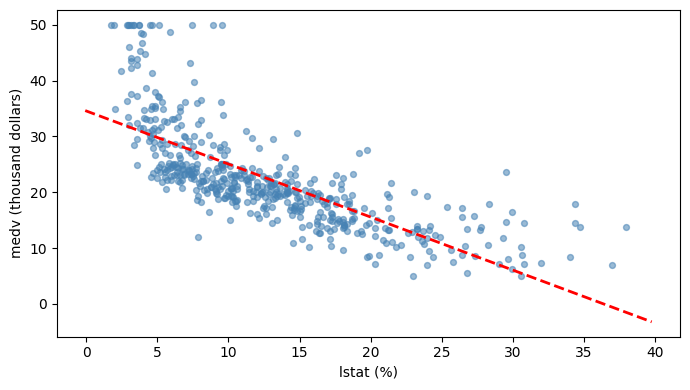

In [52]:
def abline(ax, intercept, slope, *args, **kwargs):
    x_limits = np.asarray(ax.get_xlim())
    y_limits = intercept + slope * x_limits
    ax.plot(x_limits, y_limits, *args, **kwargs)

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(data['lstat'], y, s=18, alpha=0.55, color='steelblue')
abline(ax, res_simple.params['intercept'],
       res_simple.params['lstat'], 'r--', linewidth=2)
ax.set_xlabel('lstat (%)')
ax.set_ylabel('medv (thousand dollars)')
fig.tight_layout()
fig.savefig(image_dir / '362-fit.png', dpi=160)
plt.show()
plt.close(fig)

**逐步读代码**

`def` 定义函数；ax是画布中的坐标轴，intercept/slope是截距和斜率。`get_xlim()` 取当前横轴两个端点；`np.asarray` 转成数组以便逐元素运算。计算端点y值，再连成直线。

`*args` 收集额外位置参数，如 `'r--'`（红色虚线）；`**kwargs` 收集关键字参数，如 `linewidth=2`。调用ax.plot时再把它们展开传入。可以先记住这个“把绘图参数传下去”的用途。

`figsize` 的单位是英寸；`s` 是点大小；`alpha` 是透明度；颜色仅服务辨认。`tight_layout` 调整留白；`savefig` 保存图；Path之间的 `/` 拼路径；`dpi` 决定位图分辨率；`show` 显示、`close` 释放图。散点有明显弯曲趋势。

<a id="ref-fig-ext-362-fit"></a>

![自定义函数并画拟合线：由配套代码实际生成。](图片/362-fit.png)

<a id="ref-code-362-07"></a>

### 代码 3.6.2-07　残差诊断

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/362-07.html)

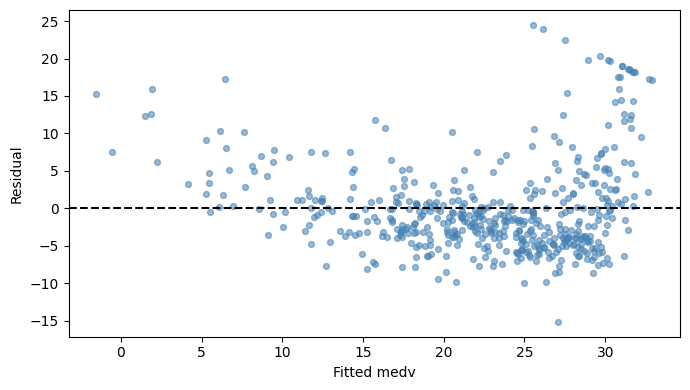

In [53]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(res_simple.fittedvalues, res_simple.resid,
           s=18, alpha=0.55, color='steelblue')
ax.axhline(0, color='black', linestyle='--')
ax.set_xlabel('Fitted medv')
ax.set_ylabel('Residual')
fig.tight_layout()
fig.savefig(image_dir / '362-residual.png', dpi=160)
plt.show()
plt.close(fig)

**逐步读代码**

`fittedvalues` 是每行拟合值，`resid` 是y减拟合值。`axhline(0)` 添加零残差参考线。持续弯曲提示均值函数形式问题；漏斗形提示方差可能随输入变化。残差不是不可观测真实误差；残差和为0也不能保证模型正确。

<a id="ref-fig-ext-362-residual"></a>

![残差诊断：由配套代码实际生成。](图片/362-residual.png)

<a id="ref-code-362-08"></a>

### 代码 3.6.2-08　杠杆值与影响点

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/362-08.html)

In [54]:
influence = res_simple.get_influence()
diagnostics = pd.DataFrame({
    'leverage': influence.hat_matrix_diag,
    'studentized_residual': influence.resid_studentized_external,
    'cooks_distance': influence.cooks_distance[0],
}, index=data.index)
position = np.argmax(diagnostics['leverage'].to_numpy())
print('largest leverage position:', position)
print('corresponding data row:')
print(data.iloc[position])
print('largest Cook distances:')
print(diagnostics.sort_values('cooks_distance', ascending=False).head().round(4))

largest leverage position: 374
corresponding data row:
lstat    37.97
medv     13.80
Name: 374, dtype: float64
largest Cook distances:
     leverage  studentized_residual  cooks_distance
374    0.0269                2.5115          0.0862
412    0.0203                2.6155          0.0700
214    0.0131                2.8076          0.0515
141    0.0204                2.0443          0.0432
373    0.0210                2.0025          0.0427


**逐步读代码**

`get_influence()` 汇总诊断量。`hat_matrix_diag` 是帽子矩阵H对角线；外学生化残差用删去该点的方差估计缩放残差；Cook距离衡量删除该点对拟合的影响。

`cooks_distance` 返回一组结果，`[0]` 取距离数组。`to_numpy()` 转数组；`np.argmax` 返回最大值位置，不是最大值，也不一定等于行标签；因此用 `.iloc[position]`。`sort_values(...,ascending=False)` 降序排列。

本例最大杠杆位置374。高杠杆、大残差、高影响并非同一概念。先核对数据与业务背景，不自动删除。Cook距离属于连接前面诊断理论的补充。

{本小节练习与参考答案}

### 练习 3.87　自由度与截距

506个观测，设计矩阵含常数与lstat两列，满秩时残差自由度是多少？

**参考答案**

为 $506-2=504$。常数列也消耗一个参数自由度；可用拟合结果的df_resid核对。

### 练习 3.88　两种预测区间

lstat=10时点预测约25.053，均值区间约[24.474,25.633]，新观测区间约[12.828,37.279]，两者分别回答什么？

**参考答案**

前者估计该输入处的条件平均medv；后者预测一个新地区的medv。后者多了新地区自身噪声，见[式（3.136）](#ref-eq-prediction-variance)。不能把它解释成单套房价预测区间。

## 多元线性回归（Multiple Linear Regression）

<a id="ref-sec-363"></a>
用不同名称保存简单、两变量、全变量拟合，避免覆盖后误把别的模型拿来比较。控制变量改变后，系数与p值可以改变；这不等于算错。

<a id="ref-code-363-01"></a>

### 代码 3.6.3-01　多元回归

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/363-01.html)

In [55]:
design_two = MS(['lstat', 'age'])
X_two = design_two.fit_transform(Boston)
res_two = sm.OLS(Boston['medv'], X_two).fit()
print(pd.DataFrame({'coef': res_two.params, 'p': res_two.pvalues}))

                coef              p
intercept  33.222761  2.943785e-180
lstat      -1.032069   8.419554e-73
age         0.034544   4.906776e-03


**逐步读代码**

两特征加截距，设计矩阵有3列。链式 `.fit()` 仍是先建立模型再拟合。此处是 medv=β0+β1*lstat+β2*age+ε。

lstat系数解释为保持age不变时的线性关联，不能拿来代替因果效应。与简单回归系数不同，是因为控制变量变了。

<a id="ref-code-363-02"></a>

### 代码 3.6.3-02　全变量与去掉一个变量

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/363-02.html)

In [56]:
terms_all = Boston.columns.drop('medv')
design_all = MS(terms_all)
X_all = design_all.fit_transform(Boston)
res_all = sm.OLS(Boston['medv'], X_all).fit()
print(pd.DataFrame({'coef': res_all.params, 'p': res_all.pvalues}))

terms_no_age = Boston.columns.drop(['medv', 'age'])
X_no_age = MS(terms_no_age).fit_transform(Boston)
res_no_age = sm.OLS(Boston['medv'], X_no_age).fit()
print('age p in full model:', res_all.pvalues['age'])

                coef             p
intercept  41.617270  3.794467e-16
crim       -0.121389  2.605302e-04
zn          0.046963  7.719966e-04
indus       0.013468  8.285201e-01
chas        2.839993  1.173458e-03
nox       -18.758022  1.502073e-06
rm          3.658119  4.808025e-17
age         0.003611  7.865948e-01
dis        -1.490754  6.170894e-13
rad         0.289405  1.843595e-05
tax        -0.012682  9.124487e-04
ptratio    -0.937533  4.630167e-12
lstat      -0.552019  6.392118e-25
age p in full model: 0.78659481144319


**逐步读代码**

`Boston.columns` 是列名索引；其 `.drop('medv')` 返回去掉目标名称后的列名，不会删除原数据列。必须排除目标，不能让y成为自己的输入。

去掉age只是演示怎样指定模型，不是按p值机械筛选。加入其他变量后age的p值会变化；p大不是证明真实效应为0。为避免覆盖此前结果，我们分别命名res_simple/res_two/res_all。

{本小节练习与参考答案}

### 练习 3.89　条件系数

lstat在简单回归中系数约-0.95，两变量回归中约-1.032，为什么可以不同？

**参考答案**

前者是边际线性拟合，后者是在控制age后的条件线性拟合。变量间相关及模型条件改变会导致系数不同。

### 练习 3.90　age不显著就无用吗

age在两变量模型中p约0.0049，全变量模型中约0.7866，能证明它绝对无用吗？

**参考答案**

不能。两种模型控制变量不同；高p只表示当前模型及假设下证据不足，不证明总体作用严格为零，也不是自动删变量的规则。

## 多元拟合优度（Multivariate Goodness of Fit）

<a id="ref-sec-364"></a>
软件的ssr在这里是残差平方和，scale为残差方差估计。对应[式（3.118）](#ref-eq-noise-estimator)、[式（3.89）](#ref-eq-tss-r2)与[式（3.164）](#ref-eq-vif-variance)。

<a id="ref-code-364-01"></a>

### 代码 3.6.4-01　拟合指标

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/364-01.html)

In [57]:
print('training R2:', res_all.rsquared)
print('adjusted R2:', res_all.rsquared_adj)
print('RSS:', res_all.ssr)
print('residual df:', res_all.df_resid)
print('RSE:', np.sqrt(res_all.scale))
print('overall F:', res_all.fvalue)
print('overall F p:', res_all.f_pvalue)

training R2: 0.7343070437613076
adjusted R2: 0.7278398724126984
RSS: 11349.418808381903
residual df: 493.0
RSE: 4.798034335596367
overall F: 113.54377426836396
overall F p: 2.2304199237254893e-133


**逐步读代码**

这里 `ssr` 指残差平方和RSS；不要把属性名误解成回归解释平方和。`scale` 是RSS/残差自由度，即s²；开方才是RSE。在含截距、满秩情形，自由度是n-p-1，p为输入项数。

R²衡量当前拟合数据上的平方误差改善；调整R²惩罚参数增加。整体F检验所有非截距系数同时为0。它们都不是独立测试误差，也不能单独证明模型假设成立。

<a id="ref-code-364-02"></a>

### 代码 3.6.4-02　VIF 与列表推导式

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/364-02.html)

In [58]:
vif_values = []
for j in range(1, X_all.shape[1]):
    value = variance_inflation_factor(X_all.to_numpy(), j)
    vif_values.append(value)

vif_table = pd.DataFrame({'VIF': vif_values}, index=X_all.columns[1:])
print(vif_table.round(3))

           VIF
crim     1.767
zn       2.298
indus    3.987
chas     1.071
nox      4.369
rm       1.913
age      3.088
dis      3.954
rad      7.445
tax      9.002
ptratio  1.797
lstat    2.871


**逐步读代码**

`[]` 创建空列表；`range(1,列数)` 从1开始到列数减1，跳过第0列截距；但完整矩阵仍传入VIF函数，使辅助回归包含截距。`append` 逐个添加值；列名切片 `[1:]` 与结果一一对应。

等价简写：`vif_values = [variance_inflation_factor(X_all.to_numpy(), j) for j in range(1, X_all.shape[1])]`。

VIF_j=1/(1-R_j²)，其中R_j²来自用其他输入解释第j个输入的辅助回归。VIF是方差膨胀倍数，标准误膨胀倍数为其平方根。高VIF提示系数辨识不稳定，不代表预测必然差，也不自动要求删变量。

{本小节练习与参考答案}

### 练习 3.91　RSE取哪个属性

scale=16时，RSE是多少？这是不是测试RMSE？

**参考答案**

RSE为4。它来自训练残差平方和除以残差自由度，不是独立测试误差的平方根。

### 练习 3.92　VIF与标准误

某变量VIF=9，方差和标准误各放大多少？

**参考答案**

固定噪声方差及该输入自身离散程度，与无信息重叠的基准比较，方差9倍、标准误3倍。参见[式（3.164）](#ref-eq-vif-variance)。

## 交互项（Interaction Terms）

<a id="ref-sec-365"></a>
交互项改变的是一个输入的斜率对另一个输入的依赖。原理回看[式（3.168）](#ref-eq-ext-interaction-change)。

<a id="ref-code-365-01"></a>

### 代码 3.6.5-01　交互项

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/365-01.html)

In [59]:
design_interaction = MS(['lstat', 'age', ('lstat', 'age')])
X_interaction = design_interaction.fit_transform(Boston)
res_interaction = sm.OLS(Boston['medv'], X_interaction).fit()
print(pd.DataFrame({'coef': res_interaction.params,
                    'p': res_interaction.pvalues}))

                coef             p
intercept  36.088536  4.907116e-88
lstat      -1.392117  8.780730e-16
age        -0.000721  9.710878e-01
lstat:age   0.004156  2.524911e-02


**逐步读代码**

列表中字符串表示主效应，元组 `('lstat','age')` 告诉MS创建两变量乘积项。模型为β0+β1*lstat+β2*age+β3*lstat*age。

固定age=a时，lstat的斜率是β1+β3*a。不能把β1看成所有地区共同的斜率；β1对应age=0时。保留主效应有助于遵循模型层级原则。

{本小节练习与参考答案}

### 练习 3.93　条件斜率

拟合项为 $-1.3921L+0.004156LA$，age=50时lstat斜率是多少？

**参考答案**

为 $-1.3921+0.004156\times50=-1.1843$，不能只取主效应-1.3921。

### 练习 3.94　交互显著就预测更好吗

交互项p=0.025，能保证独立测试误差更低吗？

**参考答案**

不能。该检验针对模型参数，预测表现还需适当验证。应结合效应大小、层级、业务支持范围与泛化误差。

## 预测变量的非线性变换（Non-linear Transformations of the Predictors）

<a id="ref-sec-366"></a>
二次项对应不同的输入函数，但模型对系数仍线性。经典部分F公式见[式（3.130）](#ref-eq-partial-f)；正交多项式换基不改变本例设计矩阵列空间，因此OLS投影不变。

<a id="ref-code-366-01"></a>

### 代码 3.6.6-01　二次项

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/366-01.html)

In [60]:
design_quad = MS([poly('lstat', degree=2, raw=True), 'age'])
X_quad = design_quad.fit_transform(Boston)
res_quad = sm.OLS(Boston['medv'], X_quad).fit()
print('columns:', list(X_quad.columns))
print(pd.DataFrame({'coef': res_quad.params, 'p': res_quad.pvalues}))

columns: ['intercept', 'poly(lstat, degree=2, raw=True)[0]', 'poly(lstat, degree=2, raw=True)[1]', 'age']
                                         coef              p
intercept                           41.288537  4.859728e-187
poly(lstat, degree=2, raw=True)[0]  -2.688300   2.569236e-68
poly(lstat, degree=2, raw=True)[1]   0.049489   7.468491e-35
age                                  0.070254   2.316450e-10


**逐步读代码**

`degree=2` 指最高二次；`raw=True` 明确生成原始lstat与lstat²两列。加age和截距，共4个参数。

模型β0+β1*lstat+β2*lstat²+β3*age，对输入非线性，但对未知系数线性，仍可用OLS。此处提前明确raw=True，方便直接解释系数；教材默认正交多项式，下一块会比较。

<a id="ref-code-366-02"></a>

### 代码 3.6.6-02　用部分F检验比较嵌套模型

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/366-02.html)

In [61]:
comparison = anova_lm(res_two, res_quad)
print(comparison.to_string())

F_manual = ((res_two.ssr - res_quad.ssr) /
            (res_two.df_resid - res_quad.df_resid)) / (
                res_quad.ssr / res_quad.df_resid)
print('F by hand:', F_manual)

   df_resid           ssr  df_diff      ss_diff           F        Pr(>F)
0     503.0  19168.128609      0.0          NaN         NaN           NaN
1     502.0  14165.613251      1.0  5002.515357  177.278785  7.468491e-35
F by hand: 177.27878523965015


**逐步读代码**

按简模型、复杂模型顺序传入。两者使用完全相同的506行响应，只差一个二次项，属于嵌套模型。

F=((RSS_R-RSS_F)/q)/(RSS_F/df_F)，这里q=1。检验的是二次项系数为0；F约177.28，p约7.47e-35，不是数学意义的0。第一行NaN是没有前一模型可比较。

经典F推断需要适当误差假设。训练拟合显著改善不等于测试误差必然改善；不能用此函数直接套在非嵌套模型或不同样本上。

<a id="ref-code-366-03"></a>

### 代码 3.6.6-03　正交多项式：换基而不改变拟合空间

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/366-03.html)

In [62]:
design_orth = MS([poly('lstat', degree=2), 'age'])
X_orth = design_orth.fit_transform(Boston)
res_orth = sm.OLS(Boston['medv'], X_orth).fit()
print('same fitted values:', np.allclose(res_quad.fittedvalues,
                                        res_orth.fittedvalues))
print('orthogonal basis coefficients:')
print(res_orth.params)

same fitted values: True
orthogonal basis coefficients:
intercept                    17.715113
poly(lstat, degree=2)[0]   -179.227870
poly(lstat, degree=2)[1]     72.990755
age                           0.070254
dtype: float64


**逐步读代码**

poly默认使用正交多项式基，得到的系数不再直接是原始x、x²的系数。两组设计矩阵在本例张成同一列空间，OLS投影相同，因此拟合值与RSS相同，系数坐标不同。这与前面矩阵观点相连，也可改善某些多项式设计的数值条件。

预测新数据时必须沿用design_orth.transform，不能重新拟合一套基。

<a id="ref-code-366-04"></a>

### 代码 3.6.6-04　比较残差图

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/366-04.html)

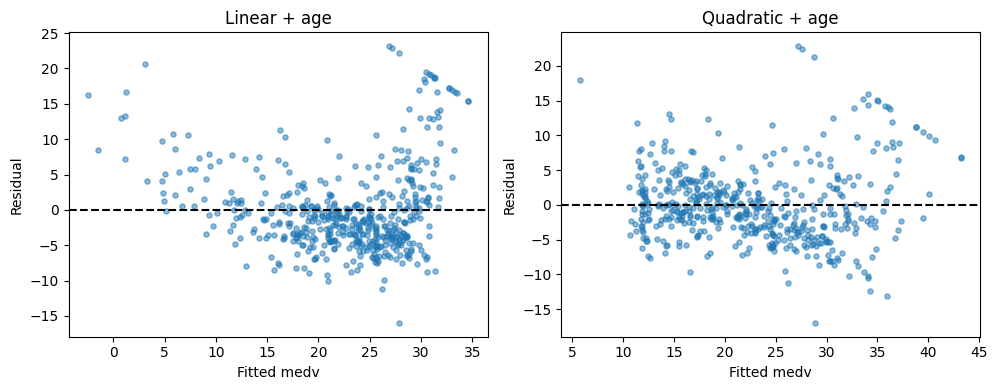

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, result, title in zip(axes, [res_two, res_quad], ['Linear + age', 'Quadratic + age']):
    ax.scatter(result.fittedvalues, result.resid, s=14, alpha=0.5)
    ax.axhline(0, color='black', linestyle='--')
    ax.set_title(title)
    ax.set_xlabel('Fitted medv')
    ax.set_ylabel('Residual')
fig.tight_layout()
fig.savefig(image_dir / '366-residuals.png', dpi=160)
plt.show()
plt.close(fig)

**逐步读代码**

`subplots(1,2)` 创建一行两图；axes装着两个坐标轴。`zip` 同时取坐标轴、结果对象和标题，每轮用匹配的三者作图。模型不同，但绘图逻辑相同，所以用循环。

观察加入二次项后残差弯曲是否减弱，并继续检查异方差、异常点等；不要用一个很小的p值宣布所有假设都正确。

<a id="ref-fig-ext-366-residuals"></a>

![比较残差图：由配套代码实际生成。](图片/366-residuals.png)

{本小节练习与参考答案}

### 练习 3.95　换基为什么系数不同

原始幂与正交多项式系数不同，但拟合值相同，是否矛盾？

**参考答案**

不矛盾。系数是不同基下的坐标；两组列张成同一子空间，投影向量相同。必须沿用训练时的设计器变换新输入。

### 练习 3.96　模型比较的条件

能否把不同样本、不同响应的两个模型传入部分F比较？

**参考答案**

不能据此作有效部分F解释。需要同一批响应与观测、嵌套模型，以及相应误差分布条件；新增一项时可核对 $F=t^2$。

## 定性预测变量（Qualitative Predictors）

<a id="ref-sec-367"></a>
Carseats有400个地点，Sales单位千件。分类编码应检查实际设计矩阵列名以确认参考组；不要把类别编号当连续大小。

<a id="ref-code-367-01"></a>

### 代码 3.6.7-01　定性变量的数据

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/367-01.html)

In [64]:
Carseats = load_data('Carseats')
print('shape:', Carseats.shape)
print('missing:', Carseats.isna().sum().sum())
print(Carseats['ShelveLoc'].dtype)
print(Carseats['ShelveLoc'].value_counts())

shape: (400, 11)
missing: 0
category
ShelveLoc
Medium    219
Bad        96
Good       85
Name: count, dtype: int64


**逐步读代码**

Carseats是400个地点的儿童安全座椅销量数据，Sales单位千件。ShelveLoc是陈列位置质量：Bad、Medium、Good，不能简单当连续数值0、1、2。`dtype` 查看数据类型；`value_counts()` 统计每类数量。

分类变量需要合适编码。含截距时k个类别通常使用k-1个指示变量，以免完全共线；删去哪一列决定参考组。

<a id="ref-code-367-02"></a>

### 代码 3.6.7-02　分类编码与完整销售模型

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/367-02.html)

In [65]:
all_variables = list(Carseats.columns.drop('Sales'))
terms_carseats = all_variables + [('Income', 'Advertising'), ('Price', 'Age')]
design_carseats = MS(terms_carseats)
X_carseats = design_carseats.fit_transform(Carseats)
res_carseats = sm.OLS(Carseats['Sales'], X_carseats).fit()

print('design columns:', list(X_carseats.columns))
print(pd.DataFrame({'coef': res_carseats.params, 'p': res_carseats.pvalues}))

design columns: ['intercept', 'CompPrice', 'Income', 'Advertising', 'Population', 'Price', 'ShelveLoc[Good]', 'ShelveLoc[Medium]', 'Age', 'Education', 'Urban[Yes]', 'US[Yes]', 'Income:Advertising', 'Price:Age']
                        coef              p
intercept           6.575565   2.223618e-10
CompPrice           0.092937   1.640774e-72
Income              0.010894   3.566527e-05
Advertising         0.070246   2.029896e-03
Population          0.000159   6.653296e-01
Price              -0.100806   1.738295e-34
ShelveLoc[Good]     4.848676  1.384764e-109
ShelveLoc[Medium]   1.953262   1.336388e-42
Age                -0.057947   3.181359e-04
Education          -0.020852   2.883608e-01
Urban[Yes]          0.140160   2.131713e-01
US[Yes]            -0.157557   2.907286e-01
Income:Advertising  0.000751   7.290232e-03
Price:Age           0.000107   4.238116e-01


**逐步读代码**

`list(...)` 将列名索引转成列表；两个列表的 `+` 表示拼接，不是数值相加。这样在原有主效应之外加两组交互。MS会按照分类类型自动编码。

查看实际列名确认参考组；本次输出ShelveLoc[Good]、ShelveLoc[Medium]，因此Bad是参考组。两列均0代表Bad，不是“没有类别”。Good系数约4.8487，表示控制其他模型变量后，与Bad相比，拟合平均销量高约4.85千件；Medium约1.9533。它们不是三组原始均值之差，也不保证改变摆放位置造成相同销量增长。

Price与Age有交互，价格斜率要把主效应与交互一起解释。

<a id="ref-code-367-03"></a>

### 代码 3.6.7-03　分类变量新样本预测

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/367-03.html)

In [66]:
new_stores = Carseats.iloc[:2].drop(columns='Sales').copy()
new_store_X = design_carseats.transform(new_stores)
print(res_carseats.predict(new_store_X))

0     7.251552
1    12.221904
dtype: float64


**逐步读代码**

这里取前两行输入只是检查预测接口，不是独立测试。`.iloc[:2]` 取位置0、1；DataFrame的 `.drop(columns='Sales')` 去掉目标列；`.copy()` 创建副本。新样本必须提供需要的原始特征，沿用原设计器以保持编码和列顺序；未知类别须另行处理，不能悄悄改变参考组。

{本小节练习与参考答案}

### 练习 3.97　三个类别的编码

含截距，以Bad为参考组，Good与Medium两个指示变量如何表示Bad？为什么通常不放三列？

**参考答案**

Bad对应两列都为0。三列指示变量之和等于截距列，会造成完全共线性；使用k-1列是常见参考组编码。

### 练习 3.98　类别系数的业务含义

Good系数约4.8487，能否说把陈列改成Good一定使销量增加4.8487千件？

**参考答案**

不能。这是控制其他模型项后的拟合平均差异，参考组为Bad；观察数据关联不自动具有因果含义，也不保证个体增量。

## 工程补充：训练、验证与测试的完整流程

<a id="ref-sec-36-engineering"></a>

**补充范围与评估边界**

本段不是原书新增3.6.8标题，代码按“3.6补充”标识。因为前面已经看过整个Boston数据，下面拆分仅用于练习流程，不能声称这是完全未见数据上的最终研究评估。实际项目应在初次探索之前留出测试，并按时间、地域或群组确定划分规则。

<a id="ref-code-368-01"></a>

### 代码 3.6补充-01　在拟合前划分训练、验证、测试

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/368-01.html)

In [67]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

project_data = Boston[['lstat', 'age', 'medv']].dropna().copy()
development, test = train_test_split(project_data, test_size=0.2, random_state=42)
train, valid = train_test_split(development, test_size=0.25, random_state=42)
print('train, valid, test:', len(train), len(valid), len(test))

train, valid, test: 303 101 102


**逐步读代码**

先留20%为测试；再从80%开发集取25%作验证，约为总量20%，余下约60%训练。506不能整除，实际303、101、102。整张表划分保证输入目标配对；random_state固定伪随机划分便于复现。

这是教材外的工程补充。真实任务须在首次探索/选择前留出测试，并按时间、地域、群组等部署情境合理拆分。本例此前已查看全数据，因此末尾分数只能用于流程练习，不能包装成完全独立的最终研究证据。

<a id="ref-code-368-02"></a>

### 代码 3.6补充-02　只用训练集拟合，只用验证集选模型

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/368-02.html)

In [68]:
def make_design(name):
    if name == 'linear':
        return MS(['lstat', 'age'])
    if name == 'quadratic':
        return MS([poly('lstat', degree=2, raw=True), 'age'])
    raise ValueError('Unknown model name')

validation_errors = {}
for name in ['linear', 'quadratic']:
    design = make_design(name)
    train_X = design.fit_transform(train)
    fitted = sm.OLS(train['medv'], train_X).fit()
    valid_X = design.transform(valid)
    valid_pred = fitted.predict(valid_X)
    validation_errors[name] = mean_squared_error(valid['medv'], valid_pred)

print(pd.Series(validation_errors, name='validation MSE'))
best_name = min(validation_errors, key=validation_errors.get)
print('selected:', best_name)

linear       36.531512
quadratic    28.771773
Name: validation MSE, dtype: float64
selected: quadratic


**逐步读代码**

`make_design` 根据名称返回全新的设计器；`if` 判断分支，`return` 返回对象并结束本次函数调用，`raise ValueError` 在名称错误时明确报错。每次调用重新创建poly对象，因为其内部拟合状态不能在独立训练之间复用。

`validation_errors` 是“模型名:验证误差”的字典。每轮新建设计器，fit仅使用train，valid只做transform与predict。`mean_squared_error(真实值,预测值)` 返回均方误差，单位为目标单位的平方。

`min(...,key=validation_errors.get)` 返回验证误差最小的键名：比较依据是各名称对应的误差，不是模型名的字母顺序。此时不查看测试误差。候选项少是为初学者演示；不宣称已找到全局最佳模型。

<a id="ref-code-368-03"></a>

### 代码 3.6补充-03　规则确定后重拟合并评估

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/368-03.html)

In [69]:
final_design = make_design(best_name)
development_X = final_design.fit_transform(development)
final_result = sm.OLS(development['medv'], development_X).fit()
test_X = final_design.transform(test)
test_pred = final_result.predict(test_X)

test_mse = mean_squared_error(test['medv'], test_pred)
baseline_pred = np.full(len(test), development['medv'].mean())
baseline_mse = mean_squared_error(test['medv'], baseline_pred)

print('test MSE:', test_mse)
print('test RMSE:', np.sqrt(test_mse))
print('constant baseline MSE:', baseline_mse)

test MSE: 25.655552362302036
test RMSE: 5.065131031108873
constant baseline MSE: 75.04543037399255


**逐步读代码**

验证选择结束后，把开发集（训练+验证）用于最终拟合，提高参数估计的数据利用。此后模型规则固定。`np.full` 创建常数预测数组，常数仅从开发集目标均值计算。

RMSE=MSE的平方根，恢复为千美元单位。优于常数基线是基本检查，不意味着可直接部署。严格独立测试流程中，看到分数后不能继续依据测试挑模型，再把同一分数声称为未受选择影响的估计。

<a id="ref-code-368-04"></a>

### 代码 3.6补充-04　保存结果和环境信息

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/368-04.html)

In [70]:
prediction_table.to_csv('简单回归_预测区间.csv', index=False)
vif_table.to_csv('全变量模型_VIF.csv', index=True)

import importlib.metadata as metadata
for package in ['numpy', 'pandas', 'statsmodels', 'ISLP', 'scikit-learn']:
    print(package, metadata.version(package))

numpy 2.2.6


pandas 2.3.3
statsmodels 0.15.0
ISLP 0.4.1
scikit-learn 1.7.2


**逐步读代码**

`to_csv` 保存表格，`index=False` 不输出行索引，VIF表保留特征名索引。`importlib.metadata.version` 记录安装包版本，便于复现。CSV与图片默认保存在当前工作目录；Notebook本身的目录与内核工作目录未必相同，必要时先检查Path.cwd()。

<a id="ref-code-368-05"></a>

### 代码 3.6补充-05　补答实验思考：改用 rm 与 lstat

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/368-05.html)

In [71]:
rm_errors = {}
for degree in [1, 2]:
    terms_rm = ['rm', 'lstat'] if degree == 1 else [
        poly('rm', degree=2, raw=True), 'lstat']
    design_rm = MS(terms_rm)
    train_rm = Boston.loc[train.index]
    valid_rm = Boston.loc[valid.index]
    fitted_rm = sm.OLS(train_rm['medv'],
                      design_rm.fit_transform(train_rm)).fit()
    prediction_rm = fitted_rm.predict(design_rm.transform(valid_rm))
    rm_errors[degree] = mean_squared_error(valid_rm['medv'], prediction_rm)
print('validation MSE by rm degree:', rm_errors)
print('selected degree:', min(rm_errors, key=rm_errors.get))

validation MSE by rm degree: {1: 28.44208381935123, 2: 20.55967243996897}
selected degree: 2


**逐步读代码**

这是此前实验最后一道开放思考题的可复现答案。继续沿用同一训练、验证行索引，不按结果重新划分。degree=1使用rm与lstat，degree=2使用rm、rm平方与lstat；每轮重建变换对象。loc按原始标签取出完整表中同一批地区。这里只用验证误差比较，没有再用已查看的测试分数挑模型；结果不等于其他划分下必然相同。

### 练习 3.99　第二次划分的分母

先留20%测试，再从剩下开发集留25%验证，训练、验证、测试约占原数据多少？

**参考答案**

约为60%、20%、20%。第二次25%的分母是开发集；506条实际得到303、101、102，受整数取样影响。

### 练习 3.100　选模后的重拟合与基线

选定二次模型后能用训练加验证重拟合吗？常数基线能用测试目标均值吗？

**参考答案**

模型规则已固定时，可用开发集重拟合，再一次评估测试。基线应从开发数据估计常数，不能用测试目标来拟合。看到测试结果后继续选模会使其不再是独立的最终评估。

## 习题（Exercises）

<a id="ref-sec-37"></a>

> 整理依据：原书3.7第1—15题按编号完整中文整理，概念题1—7、应用题8—15。原书个别“用R验证”统一改为Python；原题与下列参考解答明确分开。应用题均附实际执行结果。

**使用方式与答案边界**

先遮住米色答案框独立完成，再核对推导、对象和前提。应用题的数据版本与随机数生成顺序按代码记录；数值只代表本次运行。开放性变换与交互题给出一组可复现方案，不宣称唯一最优；探索性p值未作多重检验校正。经典t/F结论以模型及误差假设为前提。

## 第 1 题：广告预算的 p 值

<a id="ref-exercise-book3-1"></a>

**原书第 1 题**

Advertising的多元回归同时含TV、radio与newspaper。表3.4的截距估计2.939、TV为0.046、radio为0.189、newspaper为$-0.001$；前三行p值小于0.0001，报纸为0.8599。描述各行原假设，并用销量与渠道预算的业务语言解释结论，而非仅说系数为零。销量单位千件，预算单位千美元。

**参考答案**

截距检验 $H_0:\beta_0=0$：在该模型中三渠道预算均为0时的平均销量是否为0。拒绝该假设不表示零预算处一定有充分数据支持，应检查外推范围。

电视检验 $H_0:\beta_{\rm TV}=0$：固定广播和报纸预算后，平均销量是否还随电视预算线性变化。广播与报纸分别作相同的条件解释。在5%水平，电视与广播有显著额外线性关联，报纸没有足够证据拒绝零条件斜率。

广播预算增加1000美元，其他预算固定，拟合平均销量增加 $0.189\times1000=189$ 件；电视约46件。报纸系数接近0且p高，并非证明报纸任何条件下绝对无用。0.8599不是原假设成立的概率；正系数与小p也不能直接建立因果关系。此前三选一小题中只有A“控制其他渠道后证据不足”成立，B“证明完全无作用”和C“原假设有85.99%概率成立”都不成立。

## 第 2 题：KNN 分类与回归

<a id="ref-exercise-book3-2"></a>

**原书第 2 题**

仔细说明KNN分类器与KNN回归的差别。

**参考答案**

两者都先用输入距离选出K个近邻，区别在响应类型、损失及聚合方式。KNN回归对数值响应取平均，见[式（3.169）](#ref-eq-ext-knn-predict)；这是局部常数平方损失的最小化解，见[式（3.170）](#ref-eq-ext-knn-local-ls)。KNN分类统计各类别比例，在相同0--1误判代价下选比例最大类别。分类输出标签而非标签数值平均；仓库编号1、2、3不应直接平均成“仓库1.7”。两者都需要考虑K、尺度与验证；若分类错误代价不同，还须调整决策规则。

## 第 3 题：起薪、学历与交互项

<a id="ref-exercise-book3-3"></a>

**原书第 3 题**

响应是起薪（千美元）。$X_1=$GPA，$X_2=$IQ，$X_3=$Level（大学1、高中0），$X_4=$GPA$\times$IQ，$X_5=$GPA$\times$Level。估计系数依次为 $(50,20,0.07,35,0.01,-10)$。

- 固定IQ、GPA，四个说法中哪个正确？(i)高中总是更高；(ii)大学总是更高；(iii)GPA足够高时高中更高；(iv)GPA足够高时大学更高。说明原因。

- 预测IQ=110、GPA=4.0的大学毕业生起薪。

- 判断：“GPA与IQ交互系数很小，因而几乎没有交互作用证据。”

**参考答案**

（a）把学历分别代入1和0，保持其他输入相同。共同项相减，只剩

<a id="ref-eq-ext-ex3-difference"></a>

$$
\widehat Y_{\rm college}-\widehat Y_{\rm highschool}=35-10\,\mathrm{GPA}.
\tag{3.180}
$$

GPA大于3.5时差为负，因此选(iii)；小于3.5时大学更高，等于3.5时预测相同。

（b）直接代入：

<a id="ref-eq-ext-ex3-prediction"></a>

$$
\widehat Y=50+20(4)+0.07(110)+35+0.01(4)(110)-10(4)=137.1.
\tag{3.181}
$$

即137.1千美元。

（c）错误。系数大小依赖输入单位与取值；统计证据需要标准误或检验。即使0.01看似小，也不能只看小数位数判断。此交互使GPA斜率随IQ变化0.01倍IQ；缺少不确定性信息不能判断显著性。

## 第 4 题：线性与三次回归的训练及测试 RSS

<a id="ref-exercise-book3-4"></a>

**原书第 4 题**

有100个观测、一个数值输入。比较含截距的直线和三次多项式模型。

- 真实关系线性时，比较两模型训练RSS并说明理由。

- 同样真实关系下，比较测试RSS。

- 真实关系非线性但程度未知，比较训练RSS。

- 在(c)条件下比较测试RSS。

**参考答案**

（a）（c）三次模型包含直线作为 $\beta_2=\beta_3=0$ 的特例。对同一训练样本，扩大可选拟合集合，最小值不可能上升：

<a id="ref-eq-ext-ex4-nested"></a>

$$
\begin{aligned}
\min_{\beta_0,\ldots,\beta_3}\sum_i(y_i-\beta_0-\beta_1x_i-\beta_2x_i^2-\beta_3x_i^3)^2\\
\le \min_{\beta_0,\beta_1}\sum_i(y_i-\beta_0-\beta_1x_i)^2.
\end{aligned}
\tag{3.182}
$$

所以三次训练RSS不大于直线，可能相等。这个代数结论不需要真实关系线性。

（b）真实均值确为直线且满足通常条件时，额外项没有真实信号却需要估计，直线通常具有更低的期望测试误差。不能据此保证每一批有限测试数据上的RSS都更低。

（d）不能仅凭“非线性”确定。三次可能降低失配偏差，但增加估计方差；还取决于真实形状、噪声、样本数和输入设计。应通过适当验证比较，不能把训练RSS的不等式直接搬到测试集。

## 第 5 题：无截距拟合值的线性组合

<a id="ref-exercise-book3-5"></a>

**原书第 5 题**

无截距回归中，$\widehat y_i=x_i\widehat\beta$，其中 $\widehat\beta=(\sum_jx_jy_j)/(\sum_jx_j^2)$。证明 $\widehat y_i=\sum_j a_{ij}y_j$，并求系数。

**参考答案**

假设 $\sum_jx_j^2>0$，避免输入全零导致无法确定斜率。把斜率公式代入，并把与求和索引j无关的因子提出：

<a id="ref-eq-ext-ex5-linear-smoother"></a>

$$
\widehat y_i=x_i\frac{\sum_jx_jy_j}{\sum_kx_k^2}
=\sum_j\left(\frac{x_ix_j}{\sum_kx_k^2}\right)y_j,
\qquad a_{ij}=\frac{x_ix_j}{\sum_kx_k^2}.
\tag{3.183}
$$

固定输入时这些权重不依赖响应。矩阵写法是 $\widehat{\mathbf y}=H\mathbf y$，$H=\mathbf x\mathbf x^\mathsf T/(\mathbf x^\mathsf T\mathbf x)$，与[式（3.115）](#ref-eq-hat-residual)同一投影思想。由于无截距，这些权重不一定非负，也不一定行和为1。

## 第 6 题：拟合直线经过均值点

<a id="ref-exercise-book3-6"></a>

**原书第 6 题**

利用 $\widehat\beta_0=\bar y-\widehat\beta_1\bar x$，证明含截距最小二乘直线经过 $(\bar x,\bar y)$。

**参考答案**

把 $x=\bar x$ 代入拟合直线：

<a id="ref-eq-ext-ex6-meanpoint"></a>

$$
\widehat y(\bar x)=\widehat\beta_0+\widehat\beta_1\bar x
=(\bar y-\widehat\beta_1\bar x)+\widehat\beta_1\bar x=\bar y.
\tag{3.184}
$$

所以该点位于直线上。这依赖含截距拟合，不应直接套到强制过原点的回归。

## 第 7 题：证明简单回归的 R² 等于相关系数平方

<a id="ref-exercise-book3-7"></a>

**原书第 7 题**

证明含截距简单回归 $R^2=r_{XY}^2$。可以假设 $\bar x=\bar y=0$。

**参考答案**

假设输入与响应都有正的样本离差平方和，避免斜率或相关系数分母为零。中心化后记 $S_{xx}=\sum_ix_i^2$、$S_{yy}=\sum_iy_i^2$、$S_{xy}=\sum_ix_iy_i$。截距为0，斜率为 $S_{xy}/S_{xx}$。由[式（3.94）](#ref-eq-tss-ess-rss)，$R^2=\mathrm{ESS}/\mathrm{TSS}$。逐项代入：

<a id="ref-eq-ext-ex7-r2"></a>

$$
\begin{aligned}
\mathrm{ESS}&=\sum_i\widehat y_i^2
=\widehat\beta_1^2 S_{xx}=\frac{S_{xy}^2}{S_{xx}},\\
R^2&=\frac{S_{xy}^2}{S_{xx}S_{yy}}
=\left(\frac{S_{xy}}{\sqrt{S_{xx}S_{yy}}}\right)^2=r_{XY}^2.
\end{aligned}
\tag{3.185}
$$

非中心化数据先减去均值即可。详细平方和交叉项消失的依据见[式（3.93）](#ref-eq-cross-zero)，不是每个样本的交叉项分别等于零。该等式是同一样本上的含截距简单回归性质，不能推广为任意多元或测试R²等于某一对相关的平方。

**应用题公共设置**

下面第8—15题的运行代码放在同一Notebook，先运行公共导入与report函数。所有表中的p值保留科学记数法，显示很小不代表数学上等于零。数字输入中的类别编码需结合数据定义解释。

<a id="ref-code-370-01"></a>

### 代码 3.7-01　章末实验公共工具与汇总函数

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/370-01.html)

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.anova import anova_lm
from ISLP import load_data
from ISLP.models import ModelSpec as MS
from pathlib import Path
image_dir = Path('图片')
image_dir.mkdir(exist_ok=True)

def report(result):
    table = pd.DataFrame({'coef': result.params, 'SE': result.bse,
                          't': result.tvalues, 'p': result.pvalues})
    print(table.to_string(float_format=lambda v: f'{v:.6g}'))
    print(f'R2={result.rsquared:.6f}, RSS={result.ssr:.6f}, '
          f'RSE={np.sqrt(result.scale):.6f}')

**逐步读代码**

先导入本组习题共同使用的工具。`def report(result)` 定义一个可重复调用的函数，result是已拟合结果。字典的键成为表头，各个Series按参数名称对齐。`lambda v` 定义临时格式化函数；`.6g` 以6位有效数字显示，保留极小p值的科学记数法。`f` 字符串把花括号内的数值放进文本；`.6f` 显示六位小数。本函数只报告结果，不重新训练。

## 第 8 题：Auto 的简单线性回归

<a id="ref-exercise-book3-8"></a>

**原书第 8 题**

- 用sm.OLS拟合mpg对horsepower的简单回归，输出系数表。回答是否有关联、强度如何、方向如何；horsepower=98时的点预测、95%平均响应置信区间和95%个体预测区间分别是什么？

- 画散点图并加最小二乘拟合线。

- 生成诊断图并解释潜在问题。

**参考答案**

（a）本次使用392个完整样本。拟合

<a id="ref-eq-ext-ex8-model"></a>

$$
\widehat{\mathrm{mpg}}=39.9359-0.157845\,\mathrm{horsepower}.
\tag{3.186}
$$

斜率标准误约0.0064455，t约$-24.4891$，p约$7.03\times10^{-81}$，在经典模型假设下有很强的负向线性关联证据。训练 $R^2\approx0.60595$，说明相对训练均值基线解释约60.6%平方波动；RSE约4.9058 mpg。这些分别描述统计证据与拟合尺度，不能互相替代。

horsepower=98时，点预测24.4671 mpg；平均响应区间约[23.9731,24.9611]，新车观测预测区间约[14.8094,34.1248]。后一种含新车噪声，所以更宽。

（b）（c）下图的平均趋势有弯曲，直线会遗漏局部结构；残差散布也提示检查方差是否恒定。最大杠杆的数组位置为115，应回查具体车辆，而不是自动删除。斜率显著不能消除模型失配；在模型不足时区间的名义覆盖率不能无条件保证。

<a id="ref-code-370-02"></a>

### 代码 3.7-02　第 8 题：马力与燃油经济性的简单回归

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/370-02.html)

In [73]:
Auto = load_data('Auto')
auto = Auto.dropna().copy()
y8 = auto['mpg']
X8 = sm.add_constant(auto[['horsepower']])
r8 = sm.OLS(y8, X8).fit()
print('rows:', len(auto))
report(r8)
new8 = pd.DataFrame({'const': [1.], 'horsepower': [98.]})
print(r8.get_prediction(new8).summary_frame().round(4).to_string())

rows: 392
                coef        SE        t            p
const        39.9359  0.717499  55.6598 1.22036e-187
horsepower -0.157845 0.0064455 -24.4891  7.03199e-81
R2=0.605948, RSS=9385.915872, RSE=4.905757
      mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  24.4671   0.2513        23.9731        24.9611       14.8094       34.1248


**逐步读代码**

`load_data` 加载教材Auto完整数据。`dropna` 在同一张表中处理缺失，防止输入目标错位。双层方括号选出单列DataFrame，`sm.add_constant` 加入全1列，列名为const。预测一行数据时显式构造与训练相同的两列，避免单行输入被自动判定为常数列而漏加截距。区间表分别给出平均响应与新车观测的不确定性。

<a id="ref-code-370-03"></a>

### 代码 3.7-03　第 8 题：散点、残差与杠杆

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/370-03.html)

max leverage position: 115


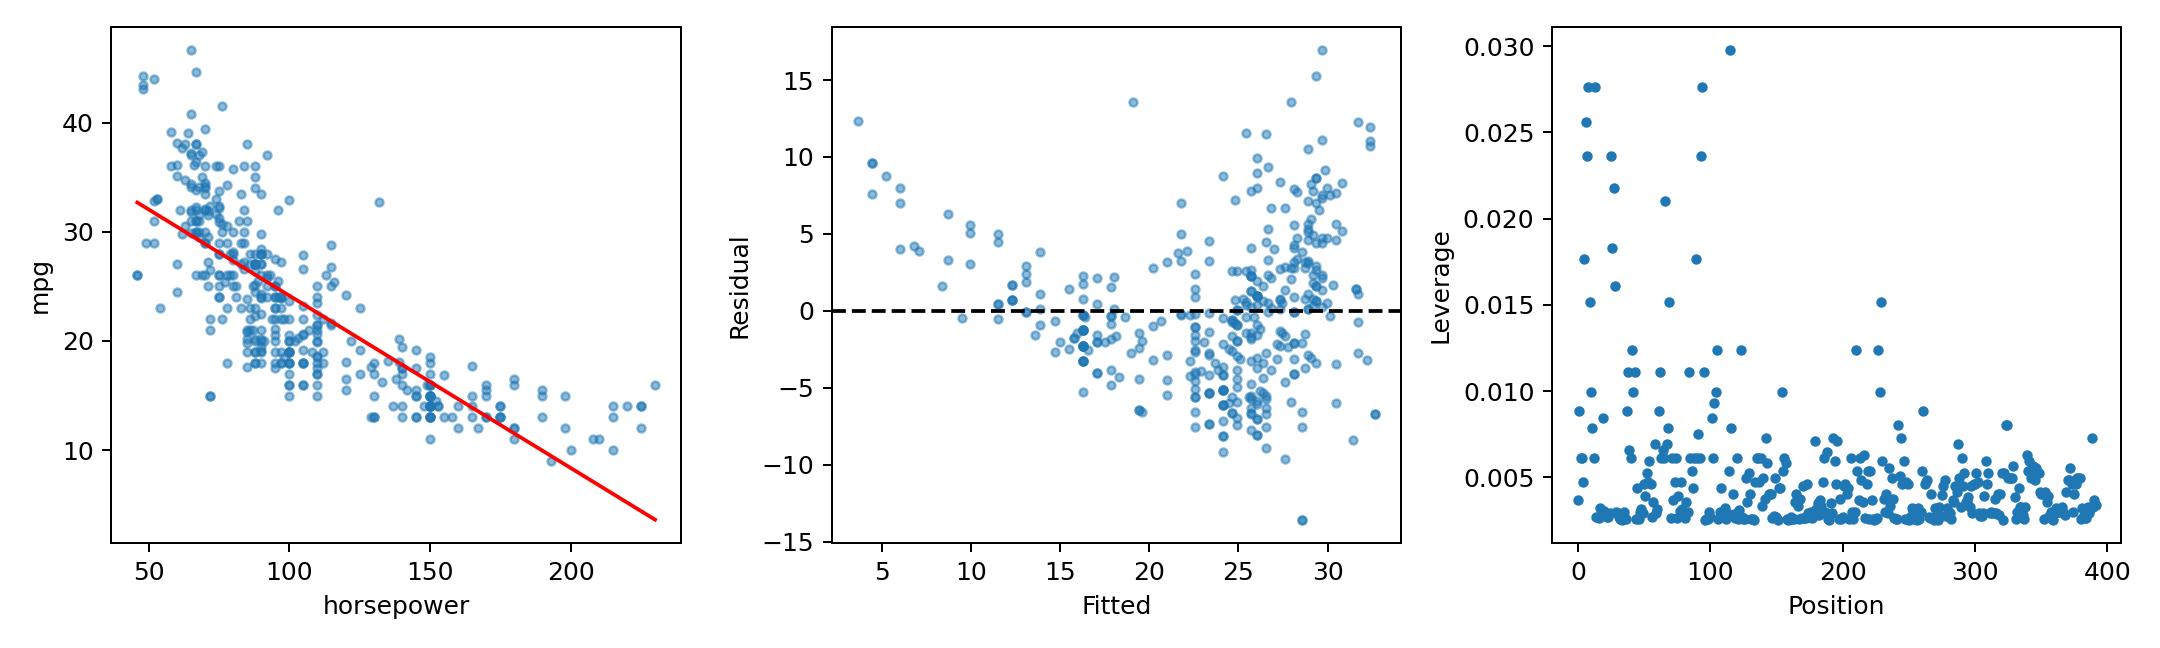

In [74]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].scatter(auto['horsepower'], y8, s=10, alpha=.5)
grid8 = np.linspace(auto['horsepower'].min(), auto['horsepower'].max(), 100)
axes[0].plot(grid8, r8.params['const'] + r8.params['horsepower'] * grid8, color='red')
axes[0].set(xlabel='horsepower', ylabel='mpg')
axes[1].scatter(r8.fittedvalues, r8.resid, s=10, alpha=.5)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(xlabel='Fitted', ylabel='Residual')
lev8 = r8.get_influence().hat_matrix_diag
axes[2].scatter(np.arange(len(auto)), lev8, s=10)
axes[2].set(xlabel='Position', ylabel='Leverage')
fig.tight_layout()
fig.savefig(image_dir / 'ex08-diagnostics.png', dpi=180)
plt.close(fig)
print('max leverage position:', np.argmax(lev8))

**逐步读代码**

`np.linspace` 生成等间隔横坐标，计算拟合直线高度后作图。`axes[0:3]`中的每个坐标轴承载不同诊断；`set`同时设置标签。`np.arange`生成0到n-1的位置，杠杆值按同样顺序绘制。保存后close释放图；本书插图读取保存文件。位置不是原始行索引标签。

<a id="ref-fig-ext-ex08-diagnostics"></a>

![第 8 题：散点、残差与杠杆：由配套代码实际生成。](图片/ex08-diagnostics.png)

## 第 9 题：Auto 的多元回归与改进

<a id="ref-exercise-book3-9"></a>

**原书第 9 题**

- 绘制数据变量的散点图矩阵。

- 用DataFrame.corr()计算相关系数矩阵。

- 用mpg为响应、除name和mpg外所有变量为输入拟合多元回归。用anova_lm判断整体关联；指出显著输入，并解释year系数。

- 生成诊断图，讨论异常残差与高杠杆观测。

- 尝试交互项，判断是否有显著交互。

- 尝试对数、平方根、平方等变换，描述结果。

**参考答案**

（a）（b）数值散点矩阵与相关矩阵见下方实际输出。mpg与weight相关约$-0.832$，与horsepower约$-0.778$；cylinders与displacement相关约0.951，提示输入冗余。车型名非数值，本版本存于索引，不参与Pearson相关。

（c）仅截距模型与全模型比较，整体F约252.428，p约$2.04\times10^{-139}$，在相应假设下拒绝所有输入斜率同时为零。按未校正的5%逐项检验，displacement、weight、year、origin显著；cylinders、horsepower、acceleration不显著。year系数约0.750773：保持其他输入固定，车型年份增加1，拟合平均mpg增加约0.751。不是仅凭观察数据证明年份本身造成改善。origin在此遵循题目按数值主效应处理，真实业务可进一步比较类别编码。

（d）最大绝对外学生化残差约4.03（mazda glc），其他柴油车型也有较大残差，提示直线可能遗漏车型差异。buick estate wagon (sw)杠杆约0.1899，明显高于平均 $8/392\approx0.0204$。图形和数值是核查线索，不是删除许可。

（e）在全部主效应上分别加入horsepower$\times$weight与weight$\times$year，p约$4.12\times10^{-23}$与$1.47\times10^{-14}$，本次探索中都有显著性证据。不要据此宣称所有样本外误差都下降。

（f）在原主效应之外分别加入horsepower平方、对数、平方根，本次p值都很小，调整R²约0.8522、0.8562、0.8561；这提示非线性结构。这里明确是“添加变换项”，不是替换原horsepower列。模型选择仍需验证，反复探索的名义p值没有自动校正。

<a id="ref-code-370-04"></a>

### 代码 3.7-04　第 9 题：散点矩阵与相关矩阵

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/370-04.html)

                mpg  cylinders  displacement  horsepower  weight  acceleration   year  origin
mpg           1.000     -0.778        -0.805      -0.778  -0.832         0.423  0.581   0.565
cylinders    -0.778      1.000         0.951       0.843   0.898        -0.505 -0.346  -0.569
displacement -0.805      0.951         1.000       0.897   0.933        -0.544 -0.370  -0.615
horsepower   -0.778      0.843         0.897       1.000   0.865        -0.689 -0.416  -0.455
weight       -0.832      0.898         0.933       0.865   1.000        -0.417 -0.309  -0.585
acceleration  0.423     -0.505        -0.544      -0.689  -0.417         1.000  0.290   0.213
year          0.581     -0.346        -0.370      -0.416  -0.309         0.290  1.000   0.182
origin        0.565     -0.569        -0.615      -0.455  -0.585         0.213  0.182   1.000


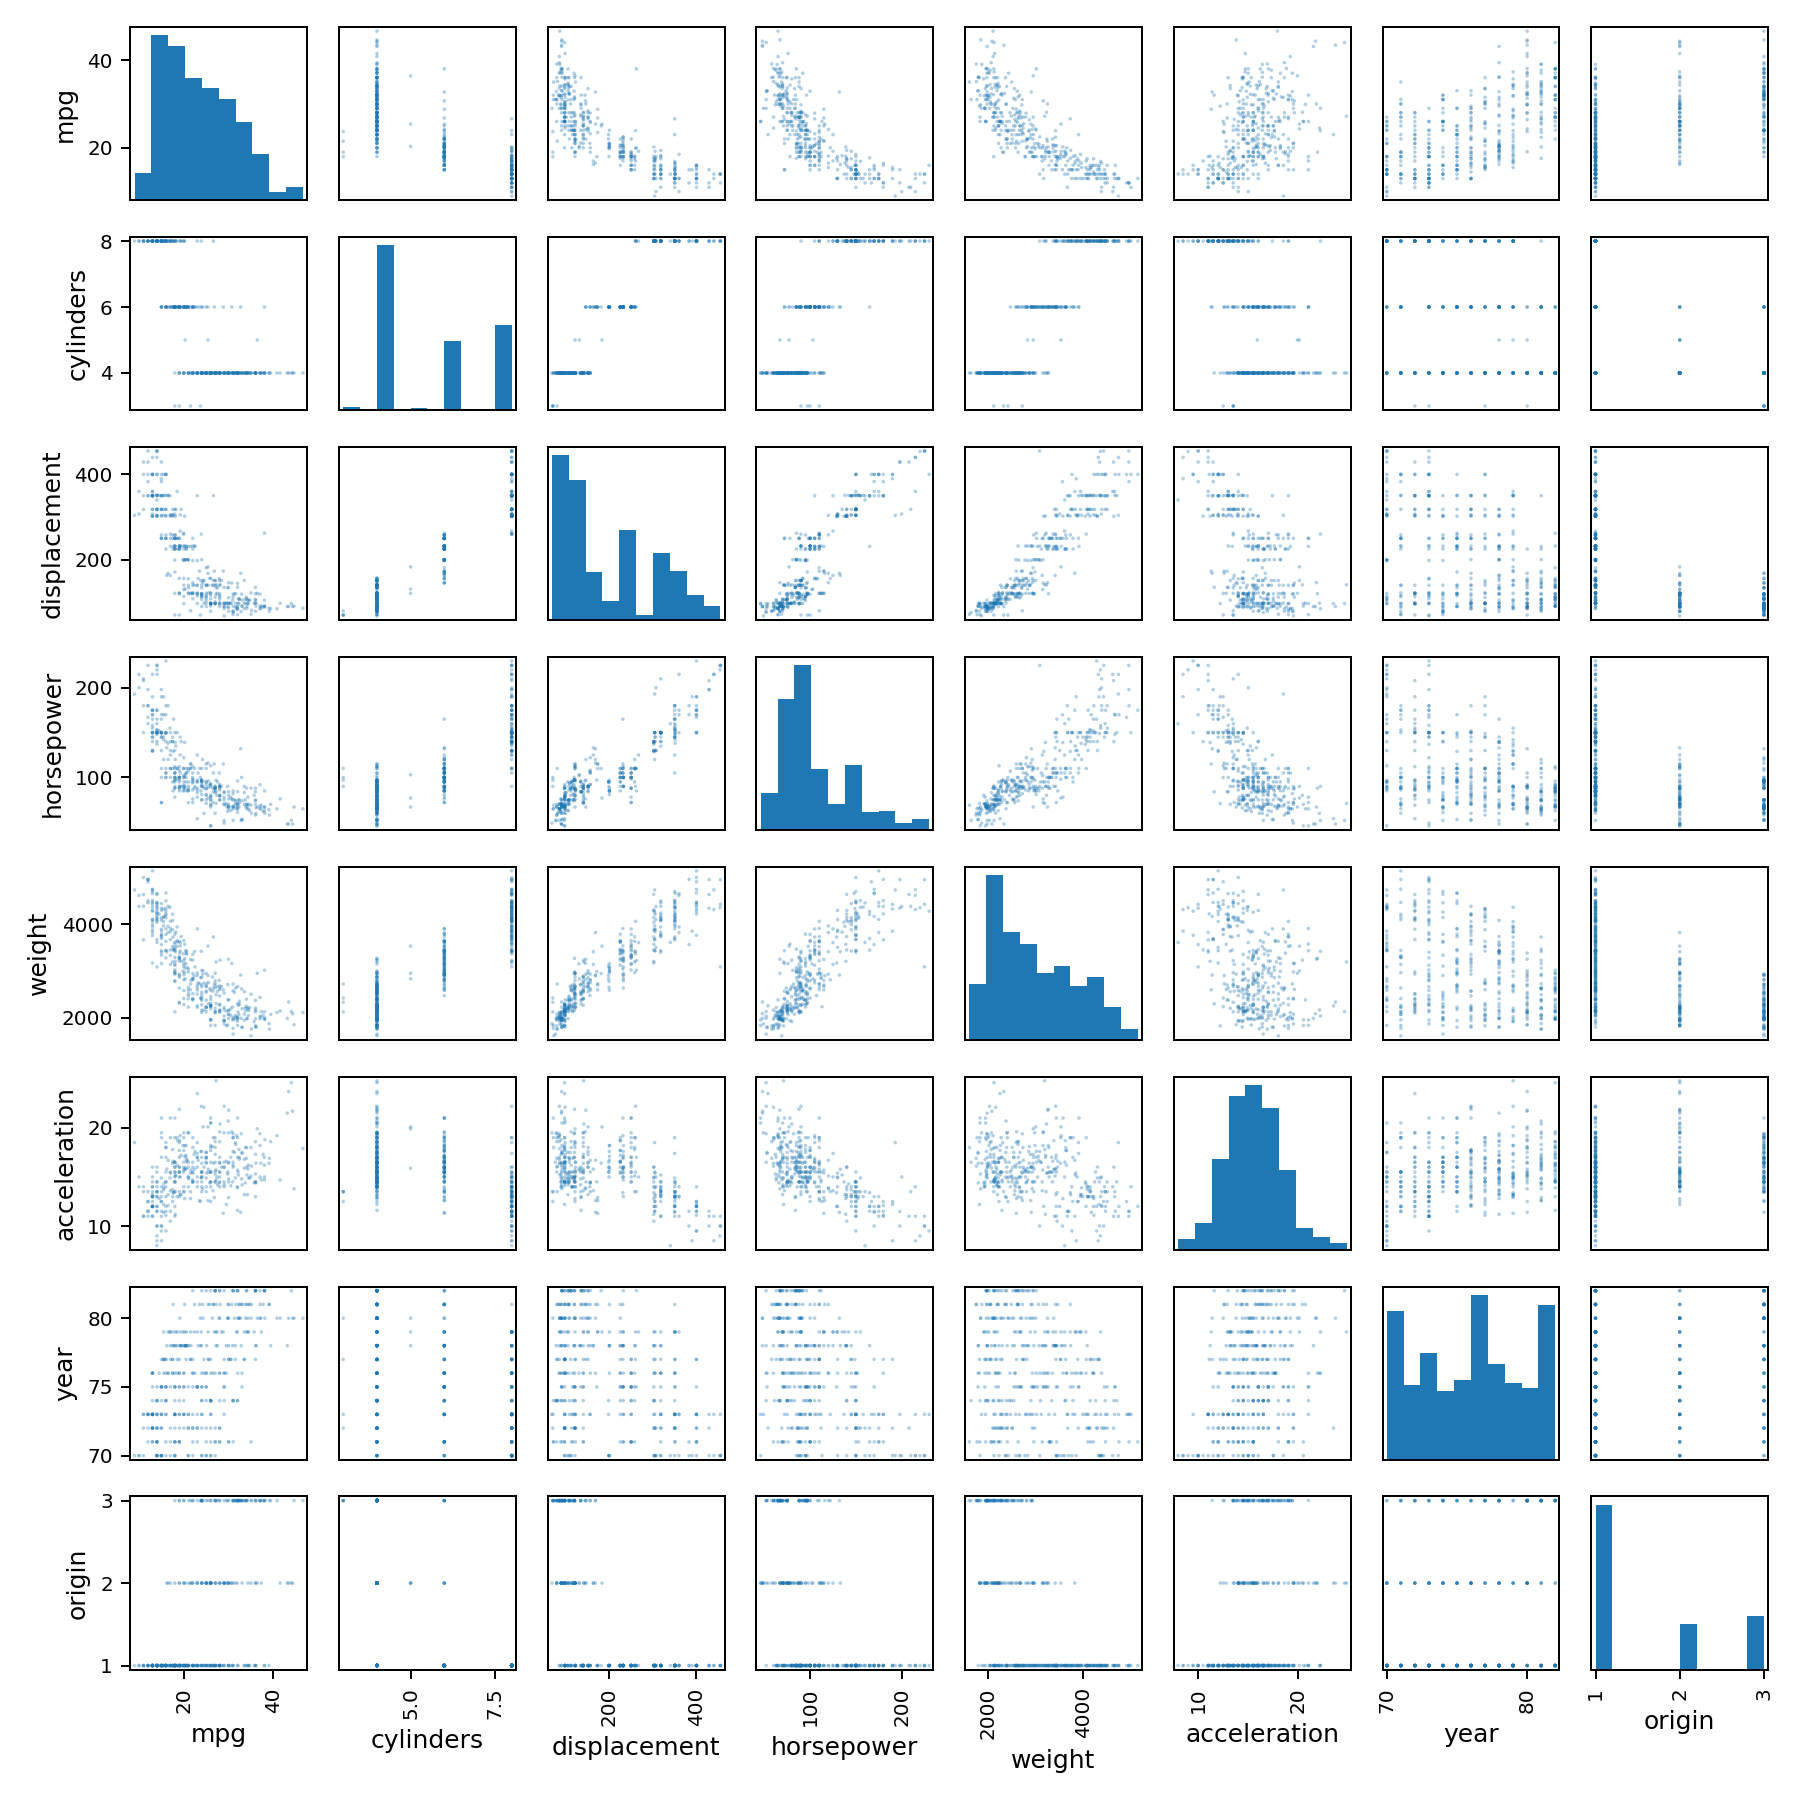

In [75]:
numeric9 = auto.select_dtypes(include='number')
pd.plotting.scatter_matrix(numeric9, figsize=(10, 10),
                           diagonal='hist', alpha=.35, s=8)
plt.tight_layout()
plt.savefig(image_dir / 'ex09-matrix.png', dpi=180)
plt.close('all')
print(numeric9.corr().round(3).to_string())

**逐步读代码**

`select_dtypes`按数据类型选列，字符串name不参与数值相关；散点矩阵对角线用直方图，其他位置是两两散点。`corr()`默认计算Pearson相关系数。origin虽以数字编码，本质是类别；本题先遵循教材的数值主效应设定，业务解释时不能忽略编码含义。

<a id="ref-fig-ext-ex09-matrix"></a>

![第 9 题：散点矩阵与相关矩阵：由配套代码实际生成。](图片/ex09-matrix.png)

<a id="ref-code-370-05"></a>

### 代码 3.7-05　第 9 题：多元回归与整体检验

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/370-05.html)

In [76]:
features9 = auto.select_dtypes(include='number').drop(columns='mpg')
X9 = sm.add_constant(features9)
r9 = sm.OLS(auto['mpg'], X9).fit()
r9_null = sm.OLS(auto['mpg'], np.ones((len(auto), 1))).fit()
report(r9)
print(anova_lm(r9_null, r9).to_string())

                    coef          SE        t           p
const           -17.2184     4.64429 -3.70744 0.000240184
cylinders      -0.493376    0.323282 -1.52615    0.127796
displacement   0.0198956  0.00751508  2.64743  0.00844465
horsepower    -0.0169511   0.0137869 -1.22951    0.219633
weight       -0.00647404 0.000652048 -9.92879 7.87495e-21
acceleration   0.0805758    0.098845 0.815174    0.415478
year            0.750773   0.0509731  14.7288 3.05598e-39
origin           1.42614    0.278136  5.12749 4.66568e-07
R2=0.821478, RSS=4252.212530, RSE=3.327682
   df_resid           ssr  df_diff       ss_diff           F         Pr(>F)
0     391.0  23818.993469      0.0           NaN         NaN            NaN
1     384.0   4252.212530      7.0  19566.780939  252.428045  2.037106e-139


**逐步读代码**

当前ISLP数据版本将车型名放在索引中；用select_dtypes选数值列再drop目标，可以适应字符串名称作为列或索引的情况。不能把mpg作为自身特征。`np.ones((n,1))`建立仅含截距的简模型；与全模型比较的F检验考察所有输入项联合是否有用。两个模型必须使用同一批响应观测。

<a id="ref-code-370-06"></a>

### 代码 3.7-06　第 9 题：诊断、交互与变换

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/370-06.html)

largest absolute studentized residuals:
                      studentized  leverage
name                                       
mazda glc                  4.0295    0.0137
vw dasher (diesel)         3.6902    0.0287
vw rabbit c (diesel)       3.4948    0.0196
largest leverage:


                         studentized  leverage
name                                          
buick estate wagon (sw)      -1.6329    0.1899
hi 1200d                      0.8037    0.0895
chevy c20                     0.4940    0.0674


hp_weight p= 4.11858e-23 adjusted R2= 0.858952
weight_year p= 1.47316e-14 adjusted R2= 0.843854
hp_squared p= 3.46978e-19 adjusted R2= 0.852202
hp_log p= 1.62103e-21 adjusted R2= 0.856246
hp_sqrt p= 1.953e-21 adjusted R2= 0.856107


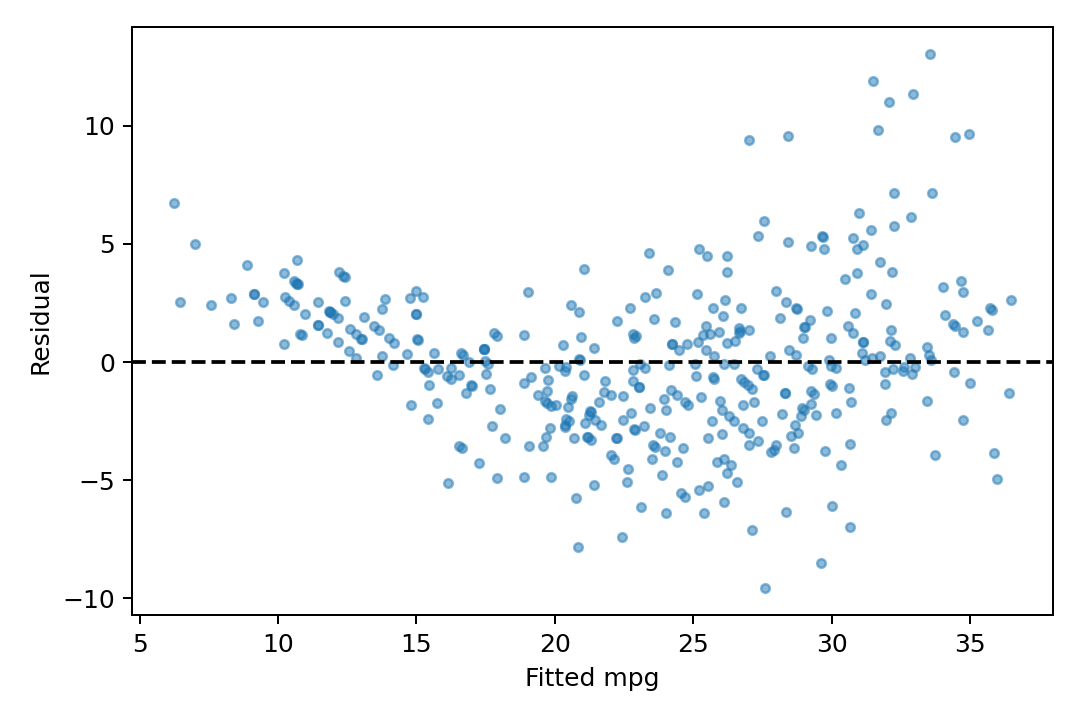

In [77]:
inf9 = r9.get_influence()
diag9 = pd.DataFrame({'studentized': inf9.resid_studentized_external,
                     'leverage': inf9.hat_matrix_diag}, index=auto.index)
print('largest absolute studentized residuals:')
print(diag9.loc[diag9['studentized'].abs().nlargest(3).index].round(4))
print('largest leverage:')
print(diag9.nlargest(3, 'leverage').round(4))
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(r9.fittedvalues, r9.resid, s=12, alpha=.5)
ax.axhline(0, color='black', linestyle='--')
ax.set(xlabel='Fitted mpg', ylabel='Residual')
fig.tight_layout(); fig.savefig(image_dir / 'ex09-residual.png', dpi=180)
plt.close(fig)
for name, values in {
    'hp_weight': auto['horsepower'] * auto['weight'],
    'weight_year': auto['weight'] * auto['year'],
    'hp_squared': auto['horsepower'] ** 2,
    'hp_log': np.log(auto['horsepower']),
    'hp_sqrt': np.sqrt(auto['horsepower']),
}.items():
    extended = X9.copy()
    extended[name] = values
    fitted9 = sm.OLS(auto['mpg'], extended).fit()
    print(name, 'p=', f'{fitted9.pvalues[name]:.6g}',
          'adjusted R2=', round(fitted9.rsquared_adj, 6))

**逐步读代码**

`abs().nlargest(3)`找绝对学生化残差最大的3个索引，`.loc`按标签取原行。每轮copy建立独立扩展矩阵，添加一列交互或变换；不让各轮累积。这里是在保留原线性主效应的基础上添加变换，检验该附加项。对数与平方根要求输入满足定义域，此数据horsepower均正。探索多个模型得到的p值应注明探索性质，训练调整R²并非测试表现。

<a id="ref-fig-ext-ex09-residual"></a>

![第 9 题：诊断、交互与变换：由配套代码实际生成。](图片/ex09-residual.png)

## 第 10 题：Carseats 的类别变量解释

<a id="ref-exercise-book3-10"></a>

**原书第 10 题**

- 用Price、Urban、US预测Sales。

- 解释每个系数，注意定性变量。

- 正确写出带类别编码的模型方程。

- 哪些输入可以拒绝系数为零的假设？

- 按(d)拟合只含有证据关联输入的较小模型。

- 比较(a)和(e)的拟合程度。

- 计算较小模型系数的95%置信区间。

- 检查较小模型的异常点与高杠杆观测。

**参考答案**

（a）—（c）以Urban=No、US=No为参考，令 $U=\mathbf1\{\mathrm{Urban=Yes}\}$、$S=\mathbf1\{\mathrm{US=Yes}\}$，拟合为

<a id="ref-eq-ext-ex10-model"></a>

$$
\widehat{\mathrm{Sales}}=13.0435-0.0544588\,\mathrm{Price}-0.0219162U+1.20057S.
\tag{3.187}
$$

Sales单位千件。控制其他输入后，价格每增加1美元，拟合平均销量减少约54.46件；城市地点相对非城市约少21.92件；美国地点相对非美国约多1200.57件。截距对应Price=0且两个类别均为No的模型均值，需谨慎看待该价格范围的外推。

（d）Price与US显著，Urban的p约0.9357，证据不足。（e）按题意去掉Urban，得到截距13.0308、Price系数$-0.0544776$、US系数1.19964。

（f）原模型训练R²约0.239275，简化模型约0.239263，几乎不变；RSE从2.47249变为2.46940。它们仅解释约24%训练平方波动，不能称为高精度预测器。

（g）简化模型95%区间：截距[11.7903,14.2713]，Price为[$-0.0648,-0.0442$]，US为[0.6915,1.7078]。

（h）最大绝对外学生化残差约2.8915，未达到常用的3倍粗筛线，但不能据此证明不存在异常。最大杠杆0.04334，高于平均0.0075及两倍平均0.015，存在值得核查的特殊输入；使用经验线不等于正式多重异常检验。

<a id="ref-code-370-07"></a>

### 代码 3.7-07　第 10 题：类别模型与简化模型

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/370-07.html)

In [78]:
car10 = load_data('Carseats')
d10 = MS(['Price', 'Urban', 'US'])
x10 = d10.fit_transform(car10)
r10 = sm.OLS(car10['Sales'], x10).fit()
report(r10)
d10_small = MS(['Price', 'US'])
x10_small = d10_small.fit_transform(car10)
r10_small = sm.OLS(car10['Sales'], x10_small).fit()
report(r10_small)
print('95% CI:'); print(r10_small.conf_int().round(4))
inf10 = r10_small.get_influence()
print('max absolute studentized residual:', np.max(np.abs(inf10.resid_studentized_external)))
print('max leverage:', np.max(inf10.hat_matrix_diag))
print('mean leverage:', np.mean(inf10.hat_matrix_diag))

                 coef         SE          t           p
intercept     13.0435   0.651012    20.0357  3.6266e-62
Price      -0.0544588 0.00524186   -10.3892 1.60992e-22
Urban[Yes] -0.0219162    0.27165 -0.0806778    0.935739
US[Yes]       1.20057   0.259042    4.63467 4.86024e-06
R2=0.239275, RSS=2420.834671, RSE=2.472492
                coef         SE        t           p
intercept    13.0308   0.630976  20.6518 7.00138e-65
Price     -0.0544776 0.00523013 -10.4161 1.27216e-22
US[Yes]      1.19964   0.258461  4.64148 4.70719e-06
R2=0.239263, RSS=2420.874462, RSE=2.469397
95% CI:
                 0        1
intercept  11.7903  14.2713
Price      -0.0648  -0.0442
US[Yes]     0.6915   1.7078


max absolute studentized residual: 2.891521318630421
max leverage: 0.0433376570371785
mean leverage: 0.007499999999999998


**逐步读代码**

MS将Urban、US的二分类变量编码为Yes指示列，参考组为No。先报告完整模型，再按题目拟合去掉Urban的模型。conf_int按系数输出区间。最后提取异常与杠杆指标作筛查；超过经验关注线只提示核查，不证明是错误数据。

<a id="ref-code-370-08"></a>

### 代码 3.7-08　第 10 题：残差与杠杆的可视化

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/370-08.html)

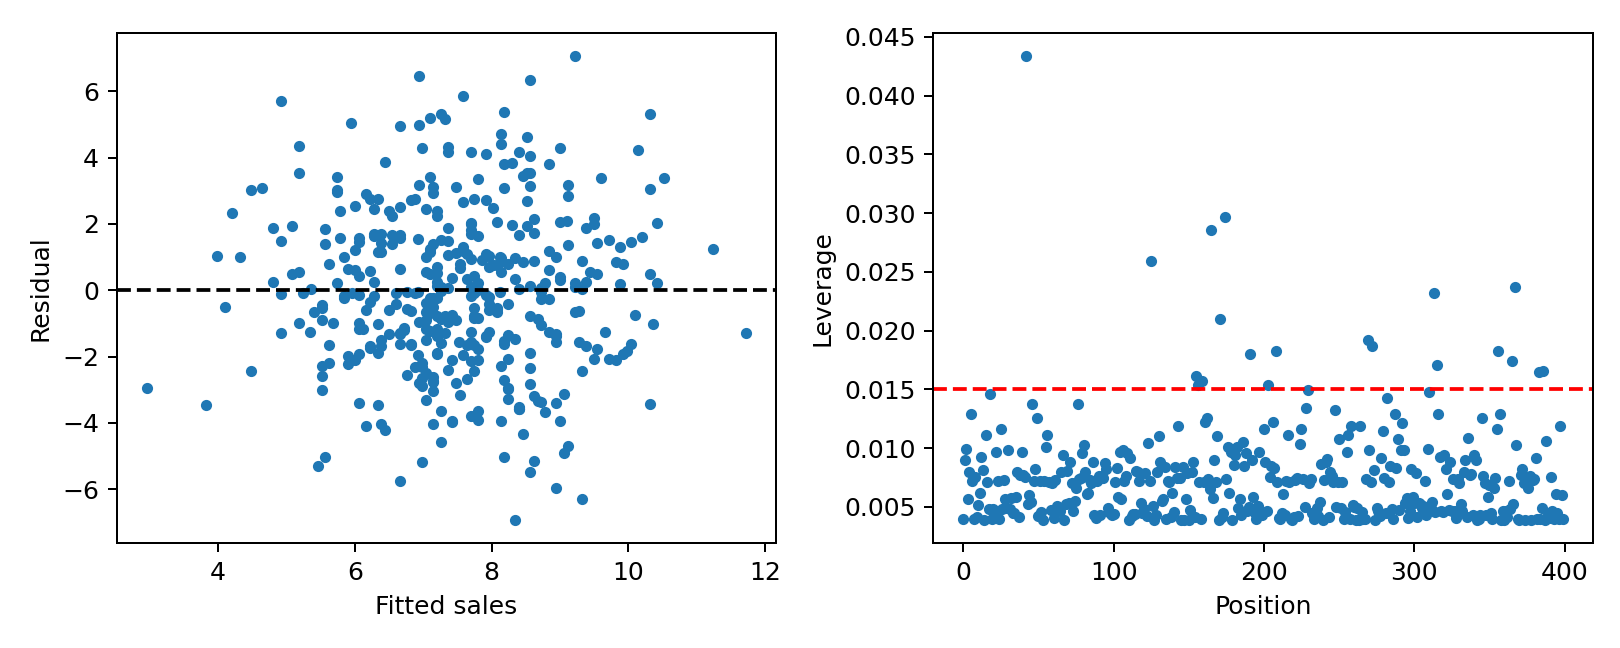

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].scatter(r10_small.fittedvalues, r10_small.resid, s=12)
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set(xlabel='Fitted sales', ylabel='Residual')
axes[1].scatter(np.arange(len(car10)), inf10.hat_matrix_diag, s=12)
axes[1].axhline(2 * x10_small.shape[1] / len(car10), color='red', linestyle='--')
axes[1].set(xlabel='Position', ylabel='Leverage')
fig.tight_layout(); fig.savefig(image_dir / 'ex10-diagnostics.png', dpi=180)
plt.close(fig)

**逐步读代码**

右图红线是2倍平均杠杆值，仅为经验筛查线；平均值为参数数目除以样本数。左图检查残差模式，右图检查特殊输入，回答的问题不同。

<a id="ref-fig-ext-ex10-diagnostics"></a>

![第 10 题：残差与杠杆的可视化：由配套代码实际生成。](图片/ex10-diagnostics.png)

## 第 11 题：交换输入与响应的 t 检验

<a id="ref-exercise-book3-11"></a>

**原书第 11 题**

先设rng=np.random.default_rng(1)，依次生成x=rng.normal(size=100)、y=2*x+rng.normal(size=100)。

- 拟合不含截距的y对x回归，报告系数、标准误、t与p。

- 交换方向，拟合不含截距的x对y，报告同样指标。

- 两组结果有什么关系？

- 已知无截距标准误为 $\sqrt{\sum_i(y_i-x_i\widehat\beta)^2/[(n-1)\sum_ix_i^2]}$，证明 $t=\sqrt{n-1}\sum_ix_iy_i/\sqrt{(\sum_ix_i^2)(\sum_iy_i^2)-(\sum_ix_iy_i)^2}$，并数值验证。

- 利用(d)解释两个方向t相同。

- 用Python验证含截距时两个方向的斜率t也相同。

**参考答案**

（a）无截距y对x：斜率1.97624，标准误0.116948，t=16.8984，p约$6.23\times10^{-31}$。（b）无截距x对y：斜率0.375744，标准误0.0222354，t与p相同。（c）斜率并非彼此倒数，但显著性检验统计量相同。

（d）令 $A=\sum_ix_i^2>0$、$B=\sum_iy_i^2>0$、$C=\sum_ix_iy_i$，并假设 $AB-C^2>0$，避免完美拟合使标准误为零。斜率为 $C/A$。平方展开：

<a id="ref-eq-ext-ex11-rss"></a>

$$
\begin{aligned}
\mathrm{RSS}&=\sum_i(y_i-x_iC/A)^2\\
&=B-2(C/A)C+(C/A)^2A
=B-C^2/A=(AB-C^2)/A.
\end{aligned}
\tag{3.188}
$$

代入无截距标准误，利用A为正：

<a id="ref-eq-ext-ex11-se"></a>

$$
\widehat{\mathrm{SE}}(\widehat\beta)
=\sqrt{\frac{(AB-C^2)/A}{(n-1)A}}
=\frac{\sqrt{AB-C^2}}{\sqrt{n-1}\,A}.
\tag{3.189}
$$

<a id="ref-eq-ext-ex11-t"></a>

$$
t=\frac{C/A}{\sqrt{AB-C^2}/(\sqrt{n-1}A)}
=\frac{\sqrt{n-1}\,C}{\sqrt{AB-C^2}}.
\tag{3.190}
$$

（e）交换x和y时，A与B交换、C不变，因此t不变，残差自由度也都是n-1，同样的t分布参考下p相同。

（f）含截距时将A、B、C换成中心化离差和，残差自由度换为n-2，同样可得

<a id="ref-eq-ext-ex11-centered-t"></a>

$$
t=r\sqrt{\frac{n-2}{1-r^2}}.
\tag{3.191}
$$

相关系数关于x和y对称，故两个方向t相同；本次含截距数值约16.73406。分布检验的有效性仍取决于各模型假设；交换方向后的代数相等不自动证明两个因果模型都成立。

<a id="ref-code-370-09"></a>

### 代码 3.7-09　第 11 题：两个方向的斜率检验

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/370-09.html)

In [80]:
rng11 = np.random.default_rng(1)
x11 = rng11.normal(size=100)
y11 = 2 * x11 + rng11.normal(size=100)
for name, response, predictor in [('y_on_x', y11, x11), ('x_on_y', x11, y11)]:
    fitted11 = sm.OLS(response, predictor).fit()
    print(name, 'without intercept')
    report(fitted11)
    with_intercept = sm.OLS(response, sm.add_constant(predictor)).fit()
    print('with intercept slope t:', with_intercept.tvalues[1])
A11 = x11 @ x11; B11 = y11 @ y11; C11 = x11 @ y11
t11 = np.sqrt(99) * C11 / np.sqrt(A11 * B11 - C11 ** 2)
print('derived t:', t11)

y_on_x without intercept
     coef       SE       t           p
0 1.97624 0.116948 16.8984 6.23155e-31
R2=0.742561, RSS=98.919970, RSE=0.999596
with intercept slope t: 16.734055202403045
x_on_y without intercept
      coef        SE       t           p
0 0.375744 0.0222354 16.8984 6.23155e-31
R2=0.742561, RSS=18.807690, RSE=0.435863
with intercept slope t: 16.734055202403038
derived t: 16.8984170630351


**逐步读代码**

default_rng(1)固定随机数流；先生成x，再生成独立噪声，顺序不可任意改变。直接把一维predictor交给sm.OLS不会自动加截距；另一轮用add_constant加入截距。`@`对一维数组是内积。无截距结果对象的R²是未中心化定义，不与含截距R²直接比较；本题重点是系数和t值。

## 第 12 题：两个方向的斜率何时相等

<a id="ref-exercise-book3-12"></a>

**原书第 12 题**

- 对于无截距回归，什么条件下y对x斜率等于x对y斜率？

- 构造100个观测，使两个斜率不同。

- 构造100个观测，使两个斜率相同。

**参考答案**

沿用第11题的A、B、C且A、B均正。两个斜率相等等价于

<a id="ref-eq-ext-ex12-equality"></a>

$$
\frac CA=\frac CB
\ \Longleftrightarrow\ C(B-A)=0
\ \Longleftrightarrow\ C=0\ \text{或}\ A=B.
\tag{3.192}
$$

不能漏掉 $C=0$ 的情形：即使长度不同，只要内积为零，两个斜率也都为零。长度相同是另一充分条件，不必逐点相同，也不必完美相关。

（b）下方第一组数据两斜率约1.92588与0.398382，不同。（c）第二组把v缩放到和u相同的二范数，两个斜率约0.391858。浮点数末位差异是数值舍入，可用allclose核对。

<a id="ref-code-370-10"></a>

### 代码 3.7-10　第 12 题：构造斜率不同与相同的样本

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/370-10.html)

In [81]:
rng12 = np.random.default_rng(12)
x12 = rng12.normal(size=100)
y12 = 2 * x12 + rng12.normal(size=100)
print('different:', (x12 @ y12) / (x12 @ x12),
      (x12 @ y12) / (y12 @ y12))
u12 = rng12.normal(size=100)
v12 = .5 * u12 + rng12.normal(size=100)
v12 = v12 * np.linalg.norm(u12) / np.linalg.norm(v12)
print('same:', (u12 @ v12) / (u12 @ u12),
      (u12 @ v12) / (v12 @ v12))

different: 1.925878530054082 0.39838197149240323
same: 0.39185787007457296 0.3918578700745728


**逐步读代码**

第一组一般具有不同的平方长度。第二组把v整体缩放到与u同样的欧氏长度；norm计算二范数。这样两种斜率的分母相同，分子也是同一个内积。它不要求两向量逐元素相同，也不要求完美相关。

## 第 13 题：模拟噪声与置信区间

<a id="ref-exercise-book3-13"></a>

**原书第 13 题**

使用种子1的默认随机数生成器。

- 生成100个标准正态输入x。

- 生成100个均值0、方差0.25的噪声eps。

- 按 $Y=-1+0.5X+\varepsilon$ 生成y；长度、真实截距与斜率是多少？

- 绘制x与y散点并解释。

- 拟合y对x直线，比较估计与真实参数。

- 同图绘制拟合直线与总体直线，添加不同颜色与图例。

- 加入x²，是否有证据改善拟合？

- 减小噪声方差，重复(a)—(f)，均值函数不变。

- 增大噪声方差，重复(a)—(f)。

- 比较原始、小噪声、大噪声时截距与斜率置信区间。

**参考答案**

（a）—（c）噪声方差0.25对应标准差0.5，normal的scale应使用标准差。y长度100，真实截距$-1$、斜率0.5。（d）散点围绕上升直线波动。（e）原始噪声下估计截距约$-1.03801$、斜率0.48429，与真实参数接近但不相等；有限样本噪声使估计随机。

（f）图中黑线是真实均值，红虚线是OLS。（g）原始数据加入二次项，p约0.95876，无足够证据反对二次项为零，与真实均值线性一致；并不是证明任何样本都不会出现假阳性。

（h）—（j）固定相同输入与标准正态噪声方向，仅改变噪声标准差为0.25、0.5、1.0（方差分别0.0625、0.25、1）。斜率95%区间依次为[0.43378,0.55051]、[0.36757,0.60102]、[0.23513,0.70203]；截距区间见实际输出。噪声越大，残差尺度越大、区间越宽。本次固定噪声方向的构造可直接比较尺度；一般独立重抽样时估计也会变化，不能要求每次区间端点单调。

<a id="ref-code-370-11"></a>

### 代码 3.7-11　第 13 题：噪声尺度与估计不确定性

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/370-11.html)

 sigma       b0      b1   b0_low  b0_high  b1_low  b1_high
  0.25 -1.01901 0.49215 -1.06889 -0.96912 0.43378  0.55051
  0.50 -1.03801 0.48429 -1.13778 -0.93824 0.36757  0.60102
  1.00 -1.07603 0.46858 -1.27556 -0.87649 0.23513  0.70203


base quadratic p: 0.9587574912263714


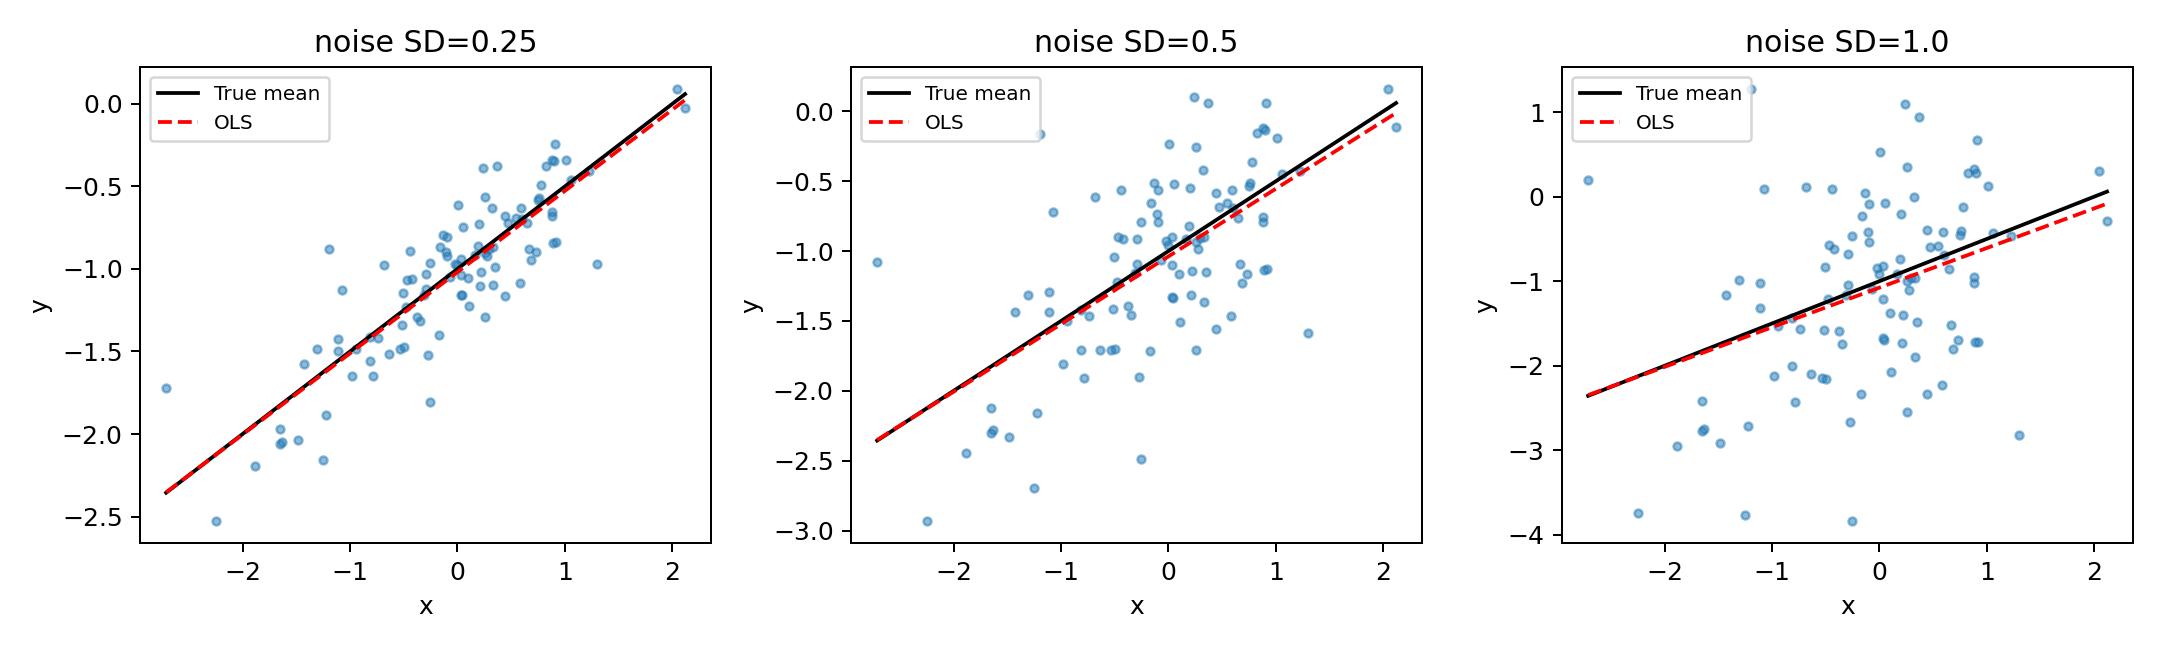

In [82]:
rng13 = np.random.default_rng(1)
x13 = rng13.normal(size=100)
z13 = rng13.normal(size=100)
X13 = sm.add_constant(x13)
rows13 = []
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, sigma in zip(axes, [.25, .5, 1.]):
    eps13 = sigma * z13
    y13 = -1 + .5 * x13 + eps13
    fitted13 = sm.OLS(y13, X13).fit()
    ci13 = fitted13.conf_int()
    rows13.append([sigma, *fitted13.params, *ci13[0], *ci13[1]])
    ax.scatter(x13, y13, s=10, alpha=.5)
    gx = np.array([x13.min(), x13.max()])
    ax.plot(gx, -1 + .5 * gx, color='black', label='True mean')
    ax.plot(gx, fitted13.params[0] + fitted13.params[1] * gx,
            color='red', linestyle='--', label='OLS')
    ax.set(title=f'noise SD={sigma}', xlabel='x', ylabel='y')
    ax.legend(fontsize=8)
table13 = pd.DataFrame(rows13, columns=['sigma','b0','b1','b0_low','b0_high','b1_low','b1_high'])
print(table13.round(5).to_string(index=False))
fig.tight_layout(); fig.savefig(image_dir / 'ex13-noise.png', dpi=180)
plt.close(fig)
y13_base = -1 + .5 * x13 + .5 * z13
quad13 = sm.OLS(y13_base, np.column_stack([np.ones(100), x13, x13 ** 2])).fit()
print('base quadratic p:', quad13.pvalues[2])

**逐步读代码**

原题噪声方差0.25对应标准差0.5。先固定x和一组标准正态噪声z，再按sigma缩放；因此三种情境只改变噪声尺度，便于公平比较，也等价于每种情境从相同种子按相同顺序重新生成。`*fitted13.params`在列表中展开两个系数，置信区间同理。`column_stack`把常数、x、x²按列拼成设计矩阵，索引2对应二次项。

<a id="ref-fig-ext-ex13-noise"></a>

![第 13 题：噪声尺度与估计不确定性：由配套代码实际生成。](图片/ex13-noise.png)

## 第 14 题：共线性和特殊观测

<a id="ref-exercise-book3-14"></a>

**原书第 14 题**

依次运行：rng=np.random.default_rng(10)；x1=rng.uniform(0,1,size=100)；x2=0.5*x1+rng.normal(size=100)/10；y=2+2*x1+0.3*x2+rng.normal(size=100)。

- 写出真实线性模型与系数。

- 计算x1与x2相关，绘制散点。

- 用x1、x2同时预测y，报告参数估计并分别检验两个斜率。

- 只用x1拟合，检验该简单模型斜率。

- 只用x2拟合，检验该简单模型斜率。

- (c)—(e)结果是否矛盾？

- 追加一个测量有误的观测 $(x_1,x_2,y)=(0.1,0.8,6)$，重新拟合三种模型。检查其对模型影响，以及在各模型中是否异常、高杠杆或兼有。

**参考答案**

（a）真实主模型 $Y=2+2X_1+0.3X_2+\varepsilon$，新生成的响应噪声均值0、方差1。（b）本次相关系数约0.77232；散点呈窄斜带，两个输入提供的信息部分重叠。

（c）联合模型估计 $(1.95791,1.61537,0.942777)$；x1的p约0.002816，可拒绝零条件斜率，x2的p约0.2594，证据不足。真实x2系数0.3不等于它在每次有限样本都显著。

（d）只用x1斜率约2.07706，p约$1.37\times10^{-8}$；（e）只用x2斜率约2.91032，p约$7.43\times10^{-7}$。（f）不矛盾：单变量模型描述边际关联，x2能间接携带x1的信息；联合模型问控制另一变量后剩多少独立信息。共线性增大条件系数标准误，见[式（3.164）](#ref-eq-vif-variance)。

（g）新增点的三种诊断量如下。外学生化残差是带符号的标准化偏离；经验阈值只用于筛查。

|模型|杠杆|外学生化残差|Cook距离|
|---|---|---|---|
|两变量|0.34767|2.78373|1.28799|
|仅x1|0.03028|4.17921|0.23383|
|仅x2|0.11021|1.34522|0.11116|

联合输入下该点明显偏离原有斜带，杠杆极高，也有偏大的响应残差，产生很强影响。联合模型斜率改为x1约0.85755、x2约2.26632，显著性结论也改变。仅x1模型中其输入仍在常见范围，杠杆不突出，但响应异常明显；仅x2模型中x2=0.8较极端，杠杆高，响应残差并不特别大。同一个观测是否特殊取决于模型使用的输入和均值关系，不能全局贴一个标签。

<a id="ref-code-370-12"></a>

### 代码 3.7-12　第 14 题：共线性下三个模型的检验

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/370-12.html)

In [83]:
rng14 = np.random.default_rng(10)
x1 = rng14.uniform(0, 1, size=100)
x2 = .5 * x1 + rng14.normal(size=100) / 10
y14 = 2 + 2 * x1 + .3 * x2 + rng14.normal(size=100)
data14 = pd.DataFrame({'x1': x1, 'x2': x2})
print('correlation:', np.corrcoef(x1, x2)[0, 1])
models14 = {}
for name, columns in [('both', ['x1','x2']), ('x1_only',['x1']), ('x2_only',['x2'])]:
    models14[name] = sm.OLS(y14, sm.add_constant(data14[columns])).fit()
    print(name); report(models14[name])

correlation: 0.772324497691354
both
          coef       SE       t          p
const  1.95791 0.189737 10.3191 2.7475e-17
x1     1.61537 0.526969 3.06539 0.00281579
x2    0.942777 0.831073 1.13441   0.259419
R2=0.290871, RSS=79.809382, RSE=0.907071
x1_only
         coef       SE       t           p
const 1.93709 0.189124 10.2425 3.60507e-17
x1    2.07706 0.335235 6.19583 1.36783e-08
R2=0.281464, RSS=80.868201, RSE=0.908397
x2_only
         coef       SE       t           p
const 2.32389 0.153652 15.1243 2.26262e-27
x2    2.91032 0.550072  5.2908 7.42958e-07
R2=0.222176, RSS=87.540715, RSE=0.945131


**逐步读代码**

uniform(0,1)生成均匀输入；x2由x1加小噪声构成，造成强相关；y噪声单独生成。corrcoef返回2×2相关矩阵，[0,1]取两变量相关系数。用字典保存三个拟合结果，不让后续模型覆盖前面的结果。

<a id="ref-code-370-13"></a>

### 代码 3.7-13　第 14 题：加入测量有误的新观测

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/370-13.html)

both
          coef       SE       t           p
const  2.06179  0.19233 10.7201 3.33427e-18
x1    0.857545 0.466483 1.83832   0.0690444
x2     2.26632 0.704713 3.21595  0.00176171
R2=0.291628, RSS=86.185210, RSE=0.937785
new point h, external residual, Cook: 0.3476716196142664 2.7837306228248013 1.2879875619115893
x1_only
         coef       SE       t           p
const 2.07394 0.201162 10.3098 2.30955e-17
x1    1.87605 0.358296 5.23602 9.23253e-07
R2=0.216871, RSS=95.280706, RSE=0.981036
new point h, external residual, Cook: 0.030283401255103554 4.179207000385163 0.23382962084011039
x2_only
         coef       SE       t           p
const 2.28401 0.151381 15.0879 2.07432e-27
x2    3.14585 0.523593  6.0082 3.12797e-08
R2=0.267201, RSS=89.157206, RSE=0.948988
new point h, external residual, Cook: 0.1102066358797133 1.3452239439030023 0.11115794899921298


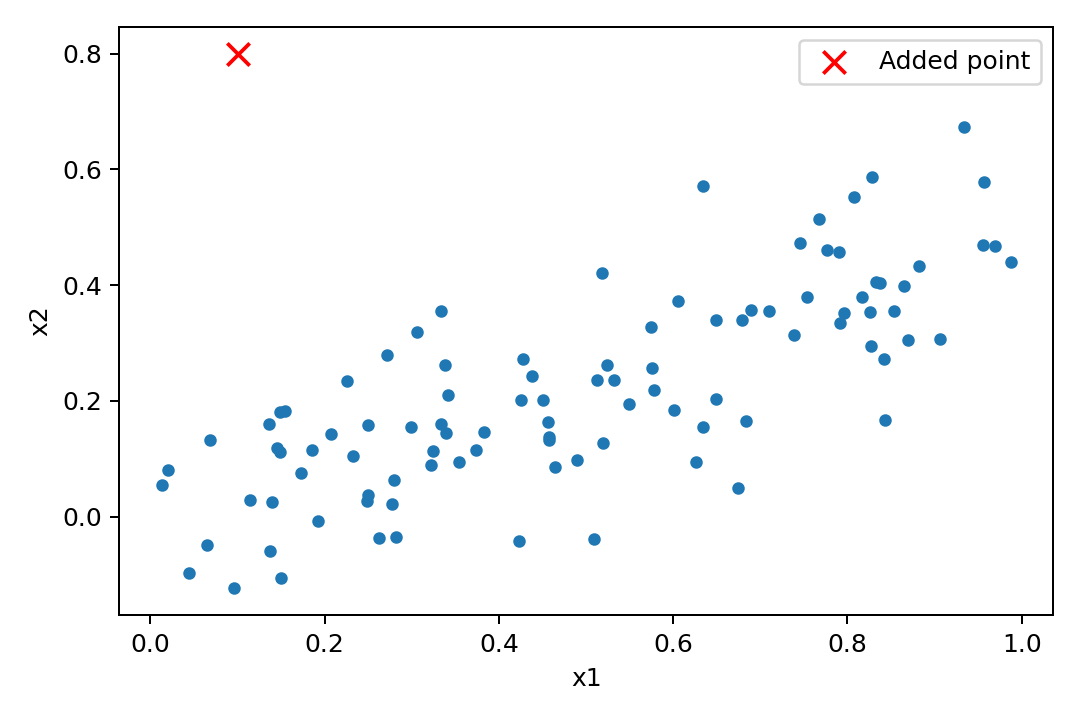

In [84]:
new14 = pd.concat([data14, pd.DataFrame({'x1':[.1], 'x2':[.8]})], ignore_index=True)
y14_new = np.concatenate([y14, [6.]])
for name, columns in [('both',['x1','x2']), ('x1_only',['x1']), ('x2_only',['x2'])]:
    fit14 = sm.OLS(y14_new, sm.add_constant(new14[columns])).fit()
    inf14 = fit14.get_influence()
    print(name); report(fit14)
    print('new point h, external residual, Cook:',
          inf14.hat_matrix_diag[-1], inf14.resid_studentized_external[-1],
          inf14.cooks_distance[0][-1])
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(x1, x2, s=16)
ax.scatter([.1], [.8], color='red', marker='x', s=80, label='Added point')
ax.set(xlabel='x1', ylabel='x2'); ax.legend()
fig.tight_layout(); fig.savefig(image_dir / 'ex14-collinearity.png', dpi=180)
plt.close(fig)

**逐步读代码**

pd.concat按行拼接原输入表与新增一行；ignore_index=True重新设置连续行标签。响应用np.concatenate按同样顺序拼接，保证配对。[-1]表示最后一个观测。重复拟合后分别查看新点在不同模型中的杠杆、外学生化残差和Cook距离；异常与高杠杆是相对于具体模型而言。

<a id="ref-fig-ext-ex14-collinearity"></a>

![第 14 题：加入测量有误的新观测：由配套代码实际生成。](图片/ex14-collinearity.png)

## 第 15 题：用 Boston 预测犯罪率

<a id="ref-exercise-book3-15"></a>

**原书第 15 题**

将crim设为响应，其余变量设为候选输入。

- 对每个输入分别做简单线性回归，描述显著性并作图。

- 同时使用所有输入做多元回归，哪些系数可以拒绝为0？

- 比较(a)(b)，作图：每个变量一个点，横坐标简单回归系数，纵坐标多元回归系数。

- 对每个输入拟合含截距三次模型 $Y=\beta_0+\beta_1X+\beta_2X^2+\beta_3X^3+\varepsilon$，判断是否有非线性关联证据。

**参考答案**

（a）以未校正5%为判断标准，本次简单模型中除chas外，其余11个输入均有显著线性关联。具体方向、p与散点见下方输出；响应极偏斜并有大值，故须谨慎使用经典推断。

（b）多元模型中zn、dis、rad、medv在5%水平显著；nox约0.06037、lstat约0.06740，不能按5%规则判显著，其他输入证据也不足。

（c）简单系数与多元系数有明显变化，甚至符号翻转，例如zn从约$-0.07394$变为0.04571。原因是边际与控制其他输入后的条件关系不同，加上共线性与模型设定；不是自动证明两种分析互相推翻。图中不同变量单位不同，不应用横纵绝对系数排序“重要性”。

（d）非线性问题应比较线性与三次模型，联合检验 $H_0:\beta_2=\beta_3=0$，不能只看三次模型整体F。使用同一响应的嵌套比较，本次11个非二元输入的联合p都小于0.05，rad约0.02608、lstat约0.03698接近阈值。这里做了多次探索性检验，不能把未校正结论当作严格总体错误率控制。

chas是0/1输入，满足 $X^2=X^3=X$，高次项不增加列空间，不能用普通“两项新增”的F检验。其余变量使用中心化后的幂以缓和数值尺度；含截距的拟合空间保持相同。此题为描述性关联练习，不能把群体层面的犯罪率回归解释为个体因果结论。

<a id="ref-code-370-14"></a>

### 代码 3.7-14　第 15 题：简单与多元回归预测犯罪率

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/370-14.html)

         simple_coef   simple_p  multiple_coef  multiple_p
zn         -0.073935 5.5065e-06        0.04571    0.015344
indus        0.50978 1.4503e-21       -0.05835     0.48571
chas         -1.8928    0.20943       -0.82538     0.48584
nox           31.249 3.7517e-23        -9.9576     0.06037
rm           -2.6841 6.3467e-07        0.62891     0.30074
age          0.10779 2.8549e-16    -0.00084828     0.96232
dis          -1.5509 8.5199e-19        -1.0122  0.00037259
rad          0.61791 2.6938e-56        0.61247  8.5881e-12
tax         0.029742 2.3571e-47     -0.0037756     0.46576
ptratio        1.152 2.9429e-11       -0.30407     0.10339
lstat         0.5488 2.6543e-27         0.1388    0.067398
medv        -0.36316  1.174e-19       -0.22006  0.00026053


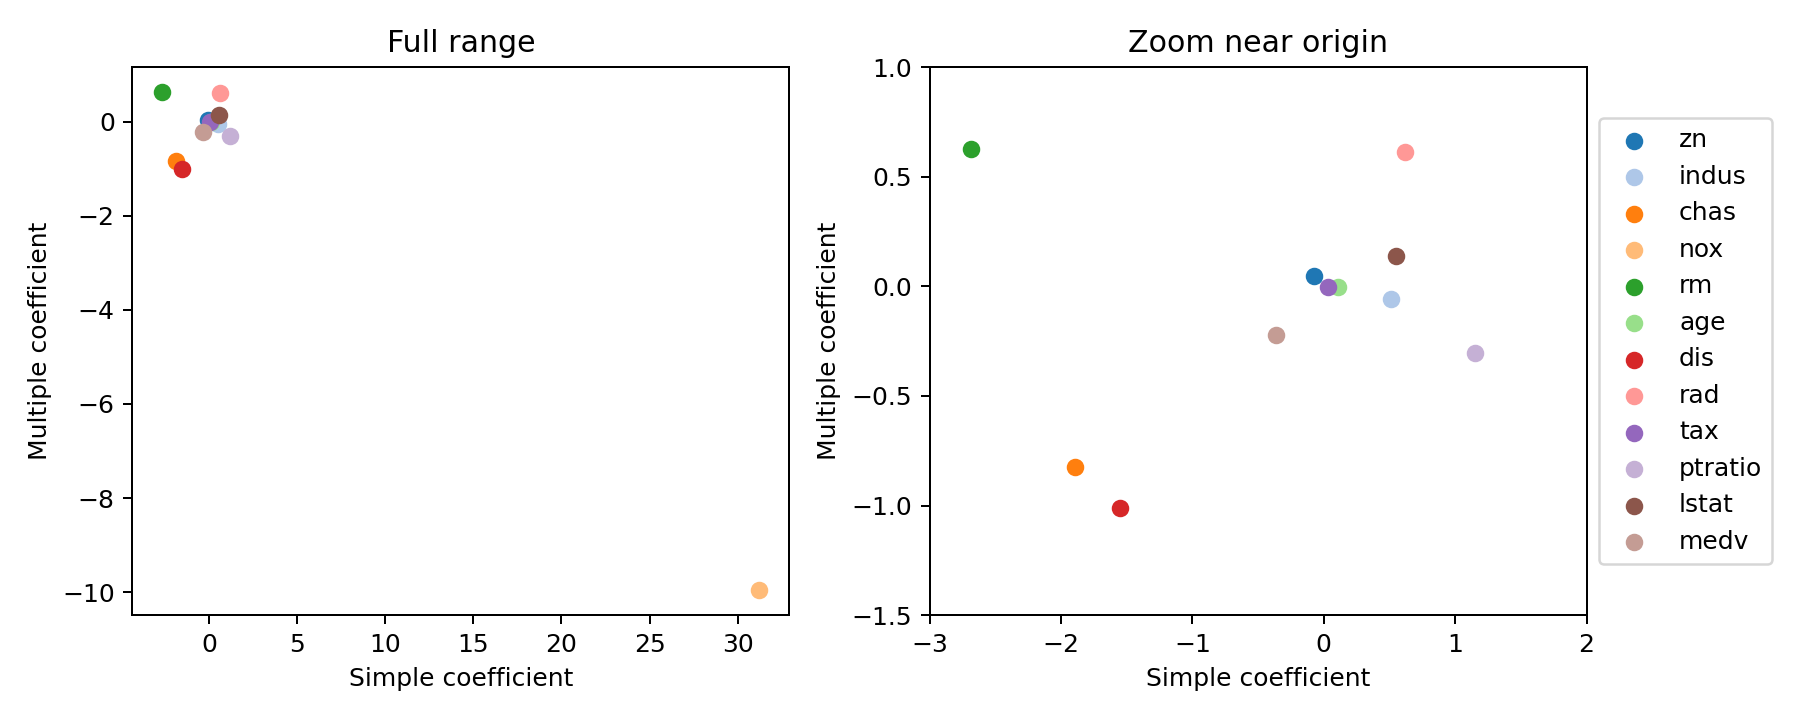

In [85]:
b15 = load_data('Boston')
y15 = b15['crim']
names15 = b15.columns.drop('crim')
simple15 = {}
for name in names15:
    simple15[name] = sm.OLS(y15, sm.add_constant(b15[[name]])).fit()
full15 = sm.OLS(y15, sm.add_constant(b15[names15])).fit()
compare15 = pd.DataFrame({
    'simple_coef': [simple15[n].params[n] for n in names15],
    'simple_p': [simple15[n].pvalues[n] for n in names15],
    'multiple_coef': full15.params[names15],
    'multiple_p': full15.pvalues[names15]}, index=names15)
print(compare15.to_string(float_format=lambda v: f'{v:.5g}'))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for j, name in enumerate(names15):
    for ax in axes:
        ax.scatter(compare15.loc[name, 'simple_coef'],
                   compare15.loc[name, 'multiple_coef'],
                   color=plt.get_cmap('tab20')(j), label=name)
for ax in axes:
    ax.set(xlabel='Simple coefficient', ylabel='Multiple coefficient')
axes[0].set_title('Full range')
axes[1].set(xlim=(-3, 2), ylim=(-1.5, 1), title='Zoom near origin')
axes[1].legend(loc='center left', bbox_to_anchor=(1, 0.5))
fig.tight_layout(); fig.savefig(image_dir / 'ex15-coefficients.png', dpi=180)
plt.close(fig)

**逐步读代码**

本题响应改为crim，其余变量包括medv都作为候选输入。每个变量单独拟合，保存到字典；列表推导式按相同变量顺序提取系数与p值。全模型则一次控制全部输入。enumerate同时给出序号j和变量名；get_cmap取调色板，序号确定颜色。内层循环把同一点画到两张图。左图保留完整范围，右图用xlim、ylim放大原点附近；legend根据label生成图例，bbox_to_anchor将图例移到图外，避免文字堆叠。不同变量单位不一样，不能按系数绝对值给“重要性”排名。

<a id="ref-fig-ext-ex15-coefficients"></a>

![第 15 题：简单与多元回归预测犯罪率：由配套代码实际生成。](图片/ex15-coefficients.png)

<a id="ref-code-370-15"></a>

### 代码 3.7-15　第 15 题：散点图与非线性联合检验

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch03/code/370-15.html)

chas : binary; powers duplicate, skip nonlinear test
variable  F_add_x2_x3            p
      zn     4.811821 8.511995e-03
   indus    31.986960 8.408754e-14
     nox    42.758171 7.122383e-18
      rm     5.308817 5.229427e-03
     age    15.140063 4.125056e-07
     dis    46.460365 3.071837e-19
     rad     3.673270 2.607832e-02
     tax    11.640023 1.144238e-05
 ptratio     8.415530 2.541647e-04
   lstat     3.319044 3.698322e-02
    medv   116.634006 2.504778e-42


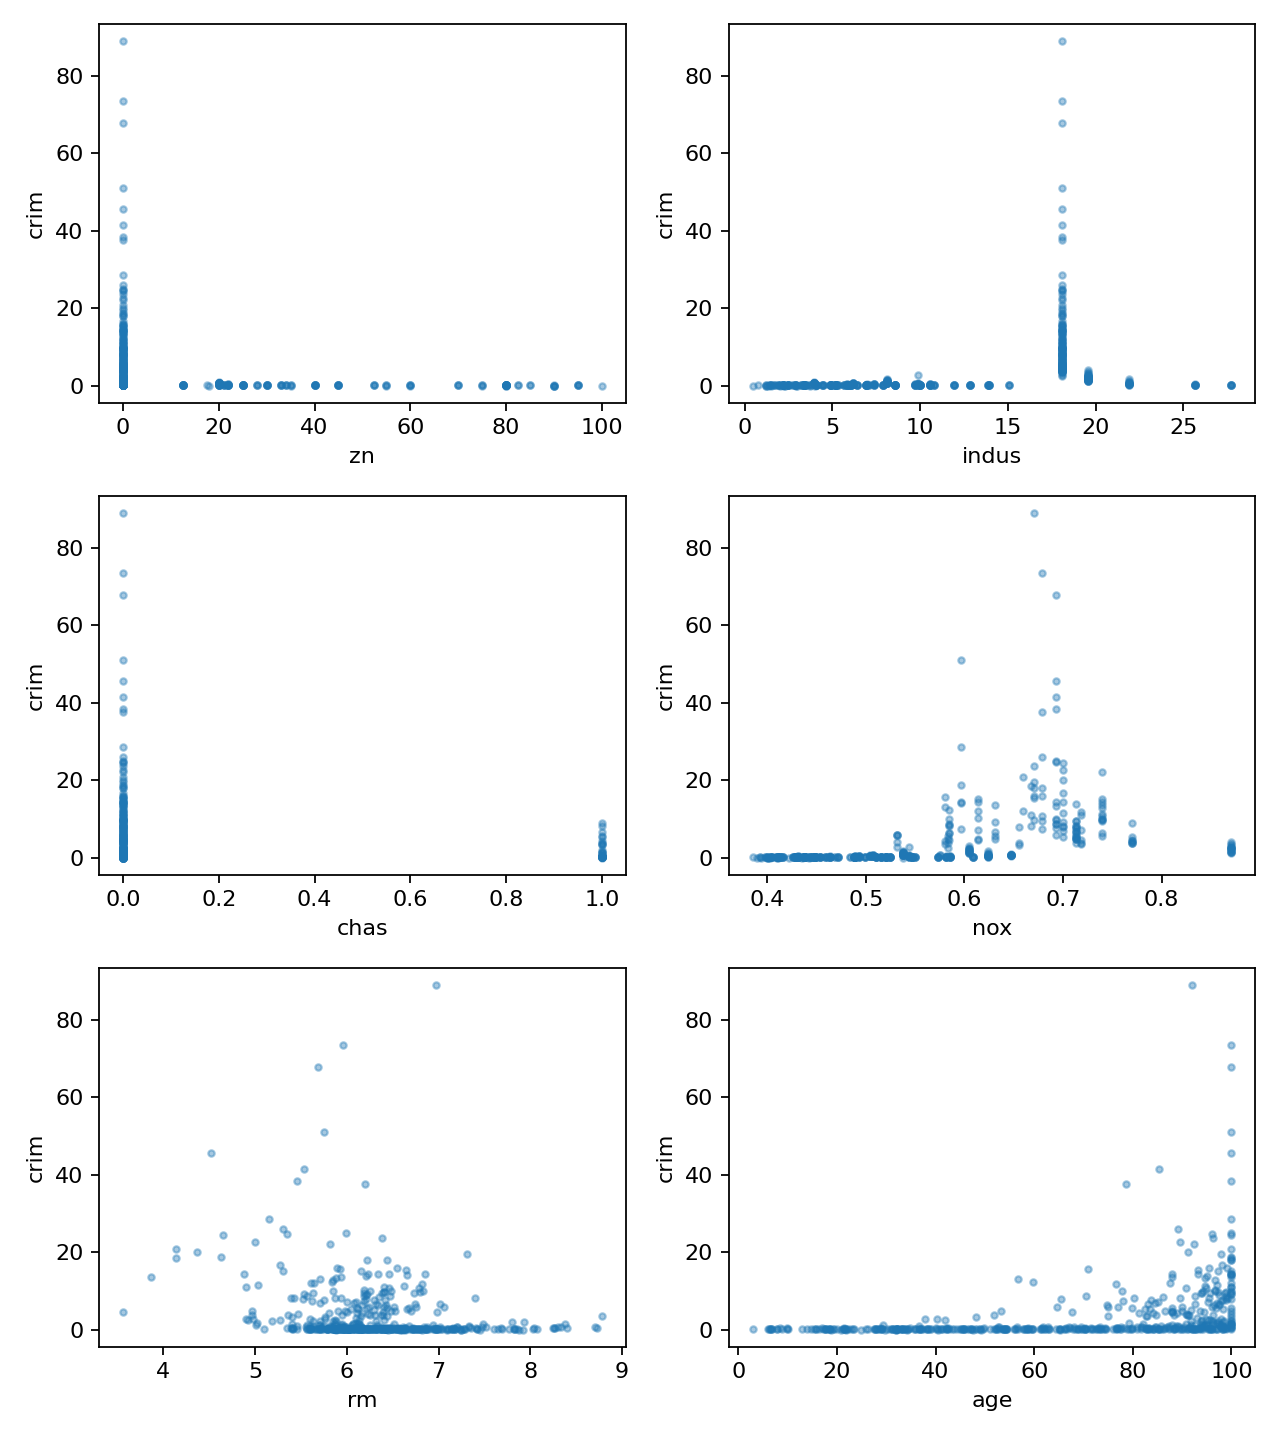

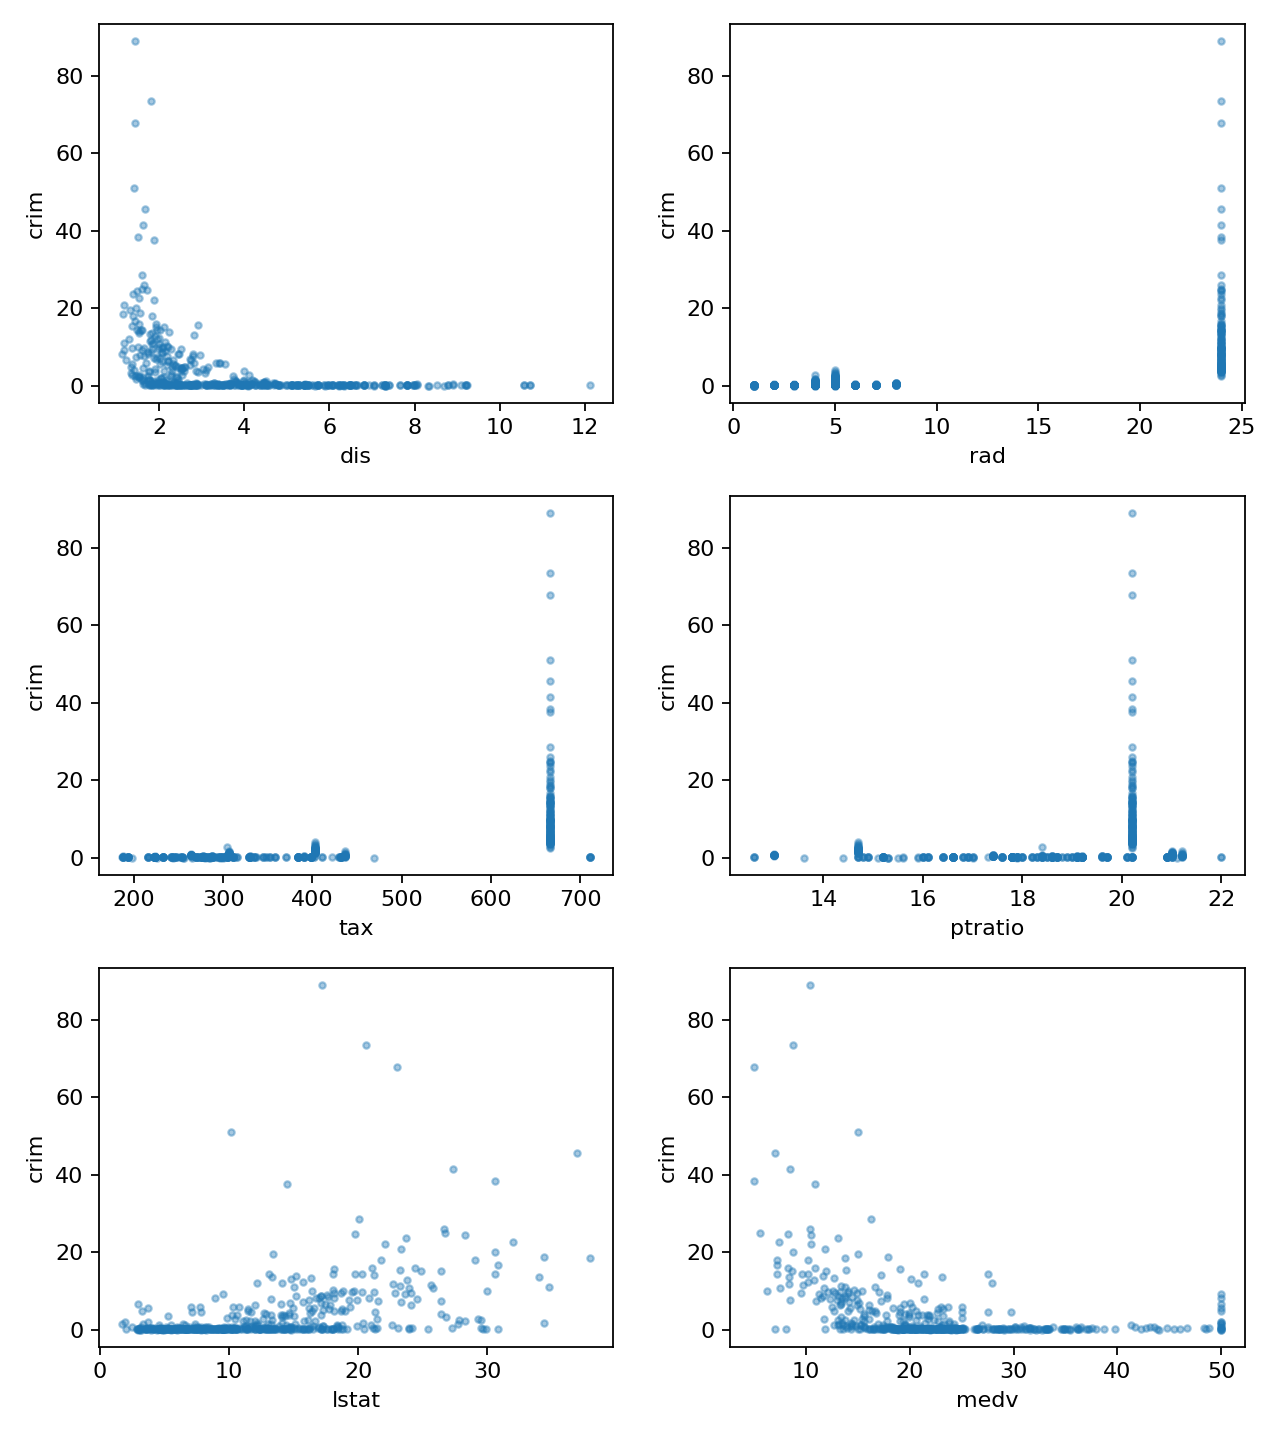

In [86]:
for page in range(2):
    fig, axes = plt.subplots(3, 2, figsize=(8, 9))
    for ax, name in zip(axes.flat, names15[page*6:(page+1)*6]):
        ax.scatter(b15[name], y15, s=8, alpha=.4)
        ax.set(xlabel=name, ylabel='crim')
    fig.tight_layout()
    fig.savefig(image_dir / f'ex15-scatter-{page+1}.png', dpi=160)
    plt.close(fig)
rows15 = []
for name in names15:
    if b15[name].nunique() <= 2:
        print(name, ': binary; powers duplicate, skip nonlinear test')
        continue
    centered = b15[name] - b15[name].mean()
    cubic = np.column_stack([np.ones(len(b15)), centered, centered**2, centered**3])
    fit15 = sm.OLS(y15, cubic).fit()
    test15 = anova_lm(simple15[name], fit15).iloc[1]
    rows15.append([name, test15['F'], test15['Pr(>F)']])
print(pd.DataFrame(rows15, columns=['variable','F_add_x2_x3','p']).to_string(index=False))

**逐步读代码**

axes.flat按顺序遍历二维坐标轴数组，每页6个变量。nunique统计不同取值数量，二元变量的平方和立方不提供新方向。先中心化x再构造高次幂，保持含截距三次多项式的拟合空间，同时减轻大数幂的数值问题。比较线性简模型与三次模型，联合检验新增二次、三次项为0；不能用三次模型整体F替代非线性检验。

<a id="ref-fig-ext-ex15-scatter-1"></a>

![第 15 题：散点图与非线性联合检验：由配套代码实际生成。](图片/ex15-scatter-1.png)

<a id="ref-fig-ext-ex15-scatter-2"></a>

![第 15 题：散点图与非线性联合检验：由配套代码实际生成。](图片/ex15-scatter-2.png)

**第三章完成后的复习路线**

先独立解释一个系数、一种区间和一个诊断图，再复现简单回归及二次改进。第5—7、11—12题把投影、正规方程与统计检验连接起来；第13—14题用可控模拟检查噪声与共线性；第8—10、15题训练真实数据分析。答案可核对，但能否关上答案重新搭建流程才是掌握程度的证据。

## 前置公式回查

以下编号沿用PDF；完整前置推导见完整版Notebook。

<a id="ref-eq-cross-zero"></a>

$$
\begin{aligned}
\sum_i(\widehat y_i-\bar y)e_i
&=\sum_i[(\widehat\beta_0-\bar y)+\widehat\beta_1x_i]e_i\\
&=(\widehat\beta_0-\bar y)\sum_i e_i+\widehat\beta_1\sum_i x_i e_i=0.
\end{aligned}
\tag{3.93}
$$

<a id="ref-eq-f-t-square"></a>

$$
F=\frac{TSS-RSS}{s^2}=\frac{ESS}{s^2}
=\frac{\widehat\beta_1^2S_{xx}}{s^2}
=\left(\frac{\widehat\beta_1}{s/\sqrt{S_{xx}}}\right)^2=T^2.
\tag{3.129}
$$

<a id="ref-eq-hat-residual"></a>

$$
H=X(X^\mathsf TX)^{-1}X^\mathsf T,\quad M=I-H,
\quad\widehat{\mathbf y}=H\mathbf y,\quad\mathbf e=M\mathbf y=M\boldsymbol\varepsilon.
\tag{3.115}
$$

<a id="ref-eq-mean-variance"></a>

$$
h_0=\mathbf z_0^\mathsf TC\mathbf z_0,
\quad\operatorname{Var}(\widehat\mu_0)
=\mathbf z_0^\mathsf T\operatorname{Cov}(\widehat{\boldsymbol\beta})\mathbf z_0
=\sigma^2h_0.
\tag{3.135}
$$

<a id="ref-eq-multi-t"></a>

$$
\frac{Z_j}{\sqrt{V/\nu}}
=\frac{\widehat\beta_j-\beta_j}{s\sqrt{C_{jj}}}\sim t_\nu,
\quad\nu=n-p-1.
\tag{3.123}
$$

<a id="ref-eq-noise-estimator"></a>

$$
s^2=\frac{\operatorname{RSS}}{\nu},\quad\mathbb E[s^2]=\sigma^2,
\quad s=\operatorname{RSE}=\sqrt{\frac{\operatorname{RSS}}{\nu}},
\quad\widehat{\operatorname{SE}}(\widehat\beta_j)=s\sqrt{C_{jj}}.
\tag{3.118}
$$

<a id="ref-eq-overall-f"></a>

$$
F=\frac{(RSS_0-RSS_F)/p}{RSS_F/(n-p-1)}.
\tag{3.125}
$$

<a id="ref-eq-partial-f"></a>

$$
F=\frac{(RSS_R-RSS_F)/k}{RSS_F/(n-p-1)}
\sim F_{k,n-p-1}\quad(H_0\text{ 下}).
\tag{3.130}
$$

<a id="ref-eq-prediction-intervals"></a>

$$
\begin{aligned}
\text{均值响应置信区间：}&\quad \widehat\mu_0\pm c s\sqrt{h_0},\\
\text{个体预测区间：}&\quad \widehat\mu_0\pm c s\sqrt{1+h_0}.
\end{aligned}
\tag{3.141}
$$

<a id="ref-eq-prediction-variance"></a>

$$
\begin{aligned}
Y_{\mathrm{new}}-\widehat\mu_0
&=(\mu_0-\widehat\mu_0)+\varepsilon_{\mathrm{new}},\\
\operatorname{Var}(Y_{\mathrm{new}}-\widehat\mu_0)
&=\operatorname{Var}(\widehat\mu_0)+\sigma^2
=\sigma^2(1+h_0).
\end{aligned}
\tag{3.136}
$$

<a id="ref-eq-residual-misspec"></a>

$$
\mathbf e=(I-H)(\boldsymbol\mu+\boldsymbol\varepsilon)
=(I-H)\boldsymbol\mu+(I-H)\boldsymbol\varepsilon.
\tag{3.155}
$$

<a id="ref-eq-rse-simple"></a>

$$
\operatorname{RSE}=s=\sqrt{\frac{\operatorname{RSS}}{n-2}}=\sqrt{\frac{32}{8}}=2.
\tag{3.87}
$$

<a id="ref-eq-simple-h"></a>

$$
h_0=\frac{\sum x_i^2-2x_0\sum x_i+nx_0^2}{nS_{xx}}
=\frac{S_{xx}+n(x_0-\bar x)^2}{nS_{xx}}
=\frac1n+\frac{(x_0-\bar x)^2}{S_{xx}}.
\tag{3.143}
$$

<a id="ref-eq-tss-ess-rss"></a>

$$
\operatorname{ESS}=\sum_i(\widehat y_i-\bar y)^2,\qquad
\operatorname{TSS}=\operatorname{ESS}+\operatorname{RSS},\qquad R^2=\frac{\operatorname{ESS}}{\operatorname{TSS}}.
\tag{3.94}
$$

<a id="ref-eq-tss-r2"></a>

$$
\operatorname{TSS}=\sum_i(y_i-\bar y)^2,\qquad
R^2=\frac{\operatorname{TSS}-\operatorname{RSS}}{\operatorname{TSS}}
=1-\frac{\operatorname{RSS}}{\operatorname{TSS}},\quad\operatorname{TSS}>0.
\tag{3.89}
$$

<a id="ref-eq-u-residual"></a>

$$
\mathbf e=(2,-1,-2,-1,2)^\mathsf T,\qquad \sum_i e_i=0.
\tag{3.154}
$$

<a id="ref-eq-vif-variance"></a>

$$
\operatorname{Var}(\widehat\beta_j\mid X)
=\frac{\sigma^2}{S_{jj}(1-R_j^2)}
=\frac{\sigma^2}{S_{jj}}\operatorname{VIF}_j.
\tag{3.164}
$$